# Factorial-Aware Asymmetric Target Fusion (FA-ATF)

## Scientifically minimal proposed-model rebuild


**Scientific goal.** Rebuild FA-ATF so that every retained component has a reproducible positive incremental contribution under training-side grouped inner cross-validation. **Inputs.** The immutable 81-row modeling table and the specimen-group outer folds established in Notebooks 01–02; model-family evidence from Notebooks 03–04 defines the bounded candidate pool. **Allowed evidence.** Only outer-training rows and their four-fold grouped inner-OOF predictions may select branches, learners, weights, residual correction, or interval widths. **Output.** One frozen target-specific architecture, genuine residual correction, outer-OOF predictions, conditional uncertainty, controlled ablations, and statistical comparisons for Notebook 06.

The factorial line-profile model is the backbone. Direct nonlinear and compact neural branches are candidates, not mandatory components. A component survives only when every inner fold improves, mean and median target-wise NRMSE improve by at least 0.005, and no inner fold degrades.


## 1. Environment, reproducibility, and immutable data contract


In [1]:
from pathlib import Path
from itertools import combinations, product
import copy
import hashlib
import json
import random
import time
import warnings

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.optimize import minimize
from scipy.stats import rankdata, wilcoxon

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from catboost import CatBoostRegressor
from statsmodels.regression.mixed_linear_model import MixedLM

import torch
from torch import nn

warnings.filterwarnings('ignore')
SEED = 20260820
FIGURE_DPI = 350
REQUIRED_FONT = 'Times New Roman'
RUN_ID = 'FA_ATF_DaKS69_Exploratory_20260820'
REBUILD_TAG = 'minimal_component_screened_20260823'

ROOT = Path.cwd().resolve()
if not (ROOT / 'dataset').exists() and (ROOT.parent / 'dataset').exists():
    ROOT = ROOT.parent

UNIFIED_DIR = ROOT / 'dataset' / 'unified'
RUN_ROOT = ROOT / 'artifacts' / RUN_ID
TABLE_ROOT = RUN_ROOT / 'Tables'
PREDICTION_DIR = TABLE_ROOT / 'Predictions'
METRIC_DIR = TABLE_ROOT / 'Metrics'
STATISTICS_DIR = TABLE_ROOT / 'Statistics'
MODEL_DIR = RUN_ROOT / 'Models'
REPORT_DIR = RUN_ROOT / 'Reports'
FIGURE_PNG_DIR = RUN_ROOT / 'Figures' / 'PNG'
FIGURE_PDF_DIR = RUN_ROOT / 'Figures' / 'PDF'
FIGURE_SOURCE_DIR = TABLE_ROOT / 'Figure_Source_Data'
for directory in (TABLE_ROOT, PREDICTION_DIR, METRIC_DIR, STATISTICS_DIR, MODEL_DIR,
                  REPORT_DIR, FIGURE_PNG_DIR, FIGURE_PDF_DIR, FIGURE_SOURCE_DIR):
    directory.mkdir(parents=True, exist_ok=True)


In [2]:
if REQUIRED_FONT not in {font.name for font in font_manager.fontManager.ttflist}:
    raise RuntimeError('Times New Roman is required for publication figures.')

mpl.rcParams.update({
    'font.family': REQUIRED_FONT,
    'font.serif': [REQUIRED_FONT],
    'mathtext.fontset': 'custom',
    'mathtext.rm': REQUIRED_FONT,
    'mathtext.it': REQUIRED_FONT + ':italic',
    'mathtext.bf': REQUIRED_FONT + ':bold',
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 17,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16,
    'figure.titlesize': 18,
    'figure.dpi': FIGURE_DPI,
    'savefig.dpi': FIGURE_DPI,
    'figure.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.grid': True,
    'grid.color': '#E7EAED',
    'grid.alpha': 0.80,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

PALETTE = {
    'blue': '#2F6B8F', 'orange': '#C77C2B', 'green': '#4F7F3A',
    'purple': '#6D5A8D', 'red': '#B45A55', 'gray': '#6E7378',
    'teal': '#4A8C8A', 'gold': '#C9A227', 'black': '#222222',
}

def validate_figure_typography(fig):
    fig.canvas.draw()
    violations = []
    for text_object in fig.findobj(match=mpl.text.Text):
        if not text_object.get_text().strip():
            continue
        size = float(text_object.get_fontsize())
        family = text_object.get_fontproperties().get_name()
        if family != REQUIRED_FONT or not (16 <= size <= 18):
            violations.append((text_object.get_text(), family, size))
    if violations:
        raise AssertionError(f'Figure typography violations: {violations}')

def save_scientific_figure(fig, stem, source_frame):
    source_frame.to_csv(FIGURE_SOURCE_DIR / f'{stem}.csv', index=False)
    validate_figure_typography(fig)
    fig.savefig(FIGURE_PNG_DIR / f'{stem}.png', dpi=FIGURE_DPI,
                bbox_inches='tight', pad_inches=0.08, facecolor='white')
    return FIGURE_PNG_DIR / f'{stem}.png'


In [3]:
# Publication-table presentation helper. It changes display only; values are untouched.
def display_grouped_table(
    frame,
    title=None,
    identifier_columns=None,
    column_groups=None,
    row_group_columns=None,
    max_rows_per_block=12,
):
    table = frame.copy()

    def _identifier_columns(columns):
        priorities = [
            "model", "model_family", "rank", "target", "Target", "variant", "Variant",
            "ablation", "comparison", "Comparison", "comparator", "Comparator",
            "class", "Class", "factor", "factor_label", "level", "condition",
            "distance_band", "metric", "Metric", "component",
            "candidate", "expert", "outer_fold", "inner_fold", "fold",
            "Feature", "feature", "Predictor", "predictor", "Variable",
            "variable", "Field", "Decision", "Analysis item", "Scientific conclusion",
            "Scientific property", "Quantity", "Scaler", "Contract item", "criterion",
            "Column", "item", "sample_id", "specimen_id", "section_id",
        ]
        selected = [column for column in priorities if column in columns]
        return selected[:4]

    def _column_groups(columns, identifiers):
        remaining = [column for column in columns if column not in identifiers]
        if len(columns) <= 7:
            return [("Complete table", remaining)]
        rules = [
            ("Predictors and design variables", (
                "hv_init", "feed", "cutting_speed", "depth_of_cut", "uncut_chip",
                "material_removal", "theoretical_roughness", "predictor", "factor",
                "formula", "unit", "level", "role", "definition", "available",
            )),
            ("Measured responses", (
                "surface_roughness", "post_process_hardness", "y_true", "y_pred",
                "lower_90", "upper_90",
            )),
            ("Predictive performance", (
                "mae", "rmse", "nrmse", "r2", "macro", "bias", "error",
                "rank", "score",
            )),
            ("Uncertainty and statistical evidence", (
                "ci_", "_ci", "confidence", "bootstrap", "coverage", "interval",
                "wilcoxon", "holm", "p_value", "_p", "probability", "effect",
                "delta", "median_fold", "sign_flip", "quantile",
            )),
            ("Computational efficiency", (
                "time", "latency", "parameter", "memory", "byte", "epoch",
                "inference", "fit_seconds", "complexity",
            )),
            ("Sample, fold, and provenance", (
                "observation", "specimen", "sample", "section", "fold", "seed",
                "rows", "columns", "matrix_rank", "condition_number", "replicate",
                "minimum", "maximum", "median", "mean", "std", "sd", "skew",
                "count", "n_", "status", "retained", "selected", "interpretation",
                "requirement", "evidence", "value",
            )),
        ]
        assigned = set()
        grouped = []
        for label, tokens in rules:
            members = [
                column for column in remaining
                if column not in assigned
                and any(token in str(column).lower() for token in tokens)
            ]
            if members:
                grouped.append((label, members))
                assigned.update(members)
        leftovers = [column for column in remaining if column not in assigned]
        if leftovers:
            grouped.append(("Additional reported attributes", leftovers))
        return grouped or [("Complete table", remaining)]

    def _split_wide_groups(groups):
        split_groups = []
        for label, columns in groups:
            if len(columns) <= 5:
                split_groups.append((label, columns))
                continue
            part_count = (len(columns) + 4) // 5
            for part_index in range(part_count):
                start = part_index * 5
                split_groups.append((
                    f"{label} (part {part_index + 1}/{part_count})",
                    columns[start:start + 5],
                ))
        return split_groups

    identifiers = (
        [column for column in identifier_columns if column in table.columns]
        if identifier_columns is not None
        else _identifier_columns(list(table.columns))
    )
    groups = (
        [(label, [column for column in columns if column in table.columns])
         for label, columns in column_groups]
        if column_groups is not None
        else _column_groups(list(table.columns), identifiers)
    )
    groups = _split_wide_groups([(label, columns) for label, columns in groups if columns])

    represented = set(identifiers)
    for _, columns in groups:
        represented.update(columns)
    missing = [column for column in table.columns if column not in represented]
    if missing:
        groups.extend(_split_wide_groups([("Additional reported attributes", missing)]))
    assert represented.union(missing) == set(table.columns)

    if row_group_columns is None and len(table) > max_rows_per_block:
        candidates = [
            "model_family", "target", "factor", "condition", "distance_band",
            "Role", "role", "component", "outer_fold", "variant", "comparator",
        ]
        row_group_columns = []
        for column in candidates:
            if column not in table.columns or column in row_group_columns:
                continue
            unique_count = table[column].nunique(dropna=False)
            if 1 < unique_count <= 10:
                row_group_columns.append(column)
                largest = table.groupby(row_group_columns, dropna=False, sort=False).size().max()
                if largest <= max_rows_per_block:
                    break
    row_group_columns = [
        column for column in (row_group_columns or []) if column in table.columns
    ]
    if row_group_columns:
        row_groups = list(table.groupby(row_group_columns, dropna=False, sort=False))
    elif len(table) > max_rows_per_block:
        row_groups = []
        for start in range(0, len(table), max_rows_per_block):
            stop = min(start + max_rows_per_block, len(table))
            noun = "models" if "model" in table.columns else "records"
            row_groups.append((
                f"{noun} {start + 1}-{stop} in displayed order",
                table.iloc[start:stop],
            ))
    else:
        row_groups = [(None, table)]

    for row_key, row_part in row_groups:
        if row_group_columns:
            values = row_key if isinstance(row_key, tuple) else (row_key,)
            row_label = "; ".join(
                f"{column}={value}" for column, value in zip(row_group_columns, values)
            )
        else:
            row_label = row_key
        for group_label, columns in groups:
            selected_columns = list(dict.fromkeys(identifiers + columns))
            heading = " — ".join(
                item for item in (title, row_label, group_label) if item
            )
            display(Markdown(f"**{heading or 'Complete table'}**"))
            with pd.option_context(
                "display.max_rows", len(row_part),
                "display.max_columns", len(selected_columns),
                "display.max_colwidth", None,
                "display.width", None,
            ):
                display(row_part[selected_columns].style.hide(axis="index"))


def display_complete_table(frame, title=None):
    """Backward-compatible alias for table cells colocated with unchanged figures."""
    return display_grouped_table(frame, title=title)

DATA_PATH = UNIFIED_DIR / 'modeling_dataset.csv'
data = pd.read_csv(DATA_PATH)

MEASURED_FEATURES = [
    'HV_init_HV30', 'feed_mm_rev', 'cutting_speed_m_min', 'depth_of_cut_mm',
]
PHYSICS_FEATURES = [
    'uncut_chip_section_mm2', 'material_removal_proxy_mm3_min',
    'theoretical_roughness_Ra_um',
]
FEATURES = MEASURED_FEATURES + PHYSICS_FEATURES
LINE_FACTORS = ['HV_init_HV30', 'feed_mm_rev', 'cutting_speed_m_min']
TARGETS = ['surface_roughness_Ra_um', 'post_process_hardness_HV30']
TARGET_LABELS = {
    TARGETS[0]: 'Surface roughness Ra (µm)',
    TARGETS[1]: 'Post-process hardness (HV30)',
}

assert data.shape[0] == 81
assert data.specimen_id.nunique() == 27
assert data.outer_fold.nunique() == 9
assert data.groupby('specimen_id').outer_fold.nunique().max() == 1
assert data[FEATURES + TARGETS].notna().all().all()

data_contract = pd.DataFrame([
    {'contract item': 'Observations', 'value': '81 sections from 27 specimens × 3 depths'},
    {'contract item': 'Predictors', 'value': '4 measured + 3 physics-guided variables'},
    {'contract item': 'Targets', 'value': 'Ra (µm); post-process hardness (HV30)'},
    {'contract item': 'Outer evaluation', 'value': '9 immutable specimen-group folds; 9 rows per fold'},
    {'contract item': 'Inner selection', 'value': '4 balanced specimen-group folds inside each outer training set'},
    {'contract item': 'Independent validation', 'value': 'Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified'},
])
display_grouped_table(data_contract, "FA-ATF modeling contract")


**FA-ATF modeling contract — Complete table**

contract item,value
Observations,81 sections from 27 specimens × 3 depths
Predictors,4 measured + 3 physics-guided variables
Targets,Ra (µm); post-process hardness (HV30)
Outer evaluation,9 immutable specimen-group folds; 9 rows per fold
Inner selection,4 balanced specimen-group folds inside each outer training set
Independent validation,Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified


**Interpretation.** The independent unit is the specimen, not the individual depth section. All preprocessing and model choices are fitted inside specimen-group training partitions. No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. Internal OOF evidence does not replace prospective independent validation.

## 2. Predeclared component-selection rule and bounded candidate budget


In [4]:
MIN_COMPONENT_GAIN = 0.005
SIMPLEX_PENALTY = 0.1
INNER_FOLDS = 4
NEURAL_SCREEN_SEEDS = 2
NEURAL_OUTER_SEEDS = 3
BOOTSTRAP_RESAMPLES = 2000

selection_rule = pd.DataFrame([
    {'criterion': 'Primary incremental endpoint', 'requirement': 'Decrease in target-wise NRMSE'},
    {'criterion': 'Mean improvement', 'requirement': f'≥ {MIN_COMPONENT_GAIN:.3f}'},
    {'criterion': 'Median improvement', 'requirement': f'≥ {MIN_COMPONENT_GAIN:.3f}'},
    {'criterion': 'Fold direction', 'requirement': 'Positive in all 4 grouped inner folds'},
    {'criterion': 'Worst inner-fold effect', 'requirement': 'Strictly positive; no accepted degradation'},
    {'criterion': 'Stochastic-branch stability', 'requirement': 'Rule must pass for ensemble mean and each of 2 independent seed realizations'},
    {'criterion': 'Fusion', 'requirement': 'Non-negative target-specific weights summing to one'},
    {'criterion': 'Outer outcomes', 'requirement': 'Unavailable to selection, weighting, residual fit, and calibration'},
])
display_grouped_table(selection_rule, "Component-retention criteria")


**Component-retention criteria — Complete table**

criterion,requirement
Primary incremental endpoint,Decrease in target-wise NRMSE
Mean improvement,≥ 0.005
Median improvement,≥ 0.005
Fold direction,Positive in all 4 grouped inner folds
Worst inner-fold effect,Strictly positive; no accepted degradation
Stochastic-branch stability,Rule must pass for ensemble mean and each of 2 independent seed realizations
Fusion,Non-negative target-specific weights summing to one
Outer outcomes,"Unavailable to selection, weighting, residual fit, and calibration"


The rule is intentionally strict because only 24 specimens are available in each outer-training partition. A branch can be scientifically interesting yet still be rejected if its incremental effect changes sign across inner folds. Rejected branches remain visible in the selection table but do not create artificial final-model ablations.


## 3. Factorial line-profile backbone


In [5]:
LINE_LEVEL_MAP = {
    feature: {value: code for value, code in zip(
        sorted(data[feature].unique()), (-1.0, 0.0, 1.0)
    )}
    for feature in LINE_FACTORS
}

def coded_line_factors(frame):
    return np.column_stack([
        frame[feature].map(LINE_LEVEL_MAP[feature]).to_numpy(dtype=float)
        for feature in LINE_FACTORS
    ])

def orthogonal_line_anova(frame, max_order=1):
    coded = coded_line_factors(frame)
    bases = [(coded[:, index], coded[:, index] ** 2 - 2.0 / 3.0)
             for index in range(3)]
    columns = []
    for order in range(1, max_order + 1):
        for factor_indices in combinations(range(3), order):
            for basis_indices in product((0, 1), repeat=order):
                value = np.ones(len(frame))
                for factor_index, basis_index in zip(factor_indices, basis_indices):
                    value *= bases[factor_index][basis_index]
                columns.append(value)
    return np.column_stack(columns)


In [6]:
def fit_line_profile_model(training_frame, target):
    specimen_lines = training_frame.groupby('specimen_id', as_index=False).agg(
        **{feature: (feature, 'first') for feature in LINE_FACTORS},
        response=(target, 'mean'),
    )
    if target == TARGETS[0]:
        model = KernelRidge(kernel='rbf', gamma=0.1, alpha=0.01)
        model.fit(coded_line_factors(specimen_lines),
                  np.log(specimen_lines.response.to_numpy()))
        transform = 'log'
    else:
        model = Pipeline([
            ('scaler', StandardScaler()),
            ('ridge', Ridge(alpha=1.0)),
        ])
        model.fit(orthogonal_line_anova(specimen_lines, 1),
                  specimen_lines.response.to_numpy())
        transform = 'raw'

    specimen_mean = training_frame.groupby('specimen_id')[target].transform('mean')
    depth_deviation = training_frame[target] - specimen_mean
    depth_profile = depth_deviation.groupby(
        training_frame.depth_of_cut_mm
    ).mean().to_dict()
    return {'model': model, 'transform': transform,
            'depth_profile': depth_profile, 'target': target}

def predict_line_profile_model(bundle, prediction_frame):
    specimen_lines = prediction_frame.groupby('specimen_id', as_index=False).agg(
        **{feature: (feature, 'first') for feature in LINE_FACTORS}
    )
    design = (coded_line_factors(specimen_lines)
              if bundle['transform'] == 'log'
              else orthogonal_line_anova(specimen_lines, 1))
    line_prediction = bundle['model'].predict(design)
    if bundle['transform'] == 'log':
        line_prediction = np.exp(line_prediction)
    prediction_by_specimen = dict(zip(specimen_lines.specimen_id, line_prediction))
    return (
        prediction_frame.specimen_id.map(prediction_by_specimen).to_numpy()
        + prediction_frame.depth_of_cut_mm.map(bundle['depth_profile']).to_numpy()
    )


## 4. Grouped inner cross-fitting and target-specific simplex fusion


In [7]:
def balanced_inner_splits(frame, n_splits, seed):
    group_info = frame[['specimen_id', 'HV_init_HV30']].drop_duplicates()
    rng = np.random.default_rng(seed)
    fold_by_group = {}
    for hardness in sorted(group_info.HV_init_HV30.unique()):
        groups = group_info.loc[
            group_info.HV_init_HV30.eq(hardness), 'specimen_id'
        ].to_numpy()
        for position, group in enumerate(rng.permutation(groups)):
            fold_by_group[group] = position % n_splits
    assignment = frame.specimen_id.map(fold_by_group).to_numpy()
    splits = [
        (np.flatnonzero(assignment != fold), np.flatnonzero(assignment == fold))
        for fold in range(n_splits)
    ]
    return splits, assignment

def fit_simplex_weights(prediction_matrix, target, penalty=SIMPLEX_PENALTY):
    n_experts = prediction_matrix.shape[1]
    if n_experts == 1:
        return np.ones(1)
    uniform = np.full(n_experts, 1.0 / n_experts)
    scale = max(np.std(target, ddof=1), 1e-12)
    def objective(weights):
        normalized_error = (target - prediction_matrix @ weights) / scale
        return (np.mean(normalized_error ** 2)
                + penalty * np.mean((weights - uniform) ** 2))
    result = minimize(
        objective, uniform, method='SLSQP',
        bounds=[(0.0, 1.0)] * n_experts,
        constraints={'type': 'eq', 'fun': lambda weights: weights.sum() - 1.0},
        options={'maxiter': 1000, 'ftol': 1e-12},
    )
    if not result.success:
        raise RuntimeError(f'Simplex optimization failed: {result.message}')
    return result.x

def crossfit_simplex(prediction_matrix, target, fold_assignment):
    prediction = np.empty(len(target))
    for fold in np.unique(fold_assignment):
        training = fold_assignment != fold
        validation = ~training
        weights = fit_simplex_weights(
            prediction_matrix[training], target[training]
        )
        prediction[validation] = prediction_matrix[validation] @ weights
    return prediction

def restricted_shared_weights(raw_weights, target_names, canonical_names):
    available = np.array([raw_weights[canonical_names.index(name)] for name in target_names], dtype=float)
    total = available.sum()
    return available / total if total > 1e-12 else np.full(len(available), 1.0 / len(available))

def fit_shared_identity_weights(selections):
    """Fit shared expert propensities without changing either target's retained expert set."""
    canonical_names = sorted({name for selection in selections.values() for name in selection['final_names']})
    initial = np.full(len(canonical_names), 1.0 / len(canonical_names))
    def objective(raw_weights):
        losses = []
        for selection in selections.values():
            weights = restricted_shared_weights(raw_weights, selection['final_names'], canonical_names)
            prediction = selection['final_matrix'] @ weights
            scale = max(np.std(selection['y_inner'], ddof=1), 1e-12)
            losses.append(np.mean(((selection['y_inner'] - prediction) / scale) ** 2))
        return float(np.mean(losses) + SIMPLEX_PENALTY * np.mean((raw_weights - initial) ** 2))
    result = minimize(
        objective, initial, method='SLSQP', bounds=[(0.0, 1.0)] * len(initial),
        constraints={'type': 'eq', 'fun': lambda weights: weights.sum() - 1.0},
        options={'maxiter': 1000, 'ftol': 1e-12},
    )
    if not result.success:
        raise RuntimeError(f'Shared-identity optimization failed: {result.message}')
    return canonical_names, result.x


In [8]:
def target_fold_nrmse(target, prediction, fold_assignment):
    scale = max(np.std(target, ddof=1), 1e-12)
    return np.array([
        np.sqrt(mean_squared_error(
            target[fold_assignment == fold],
            prediction[fold_assignment == fold],
        )) / scale
        for fold in np.unique(fold_assignment)
    ])

def incremental_contribution(target, reference, candidate, fold_assignment):
    improvement = (
        target_fold_nrmse(target, reference, fold_assignment)
        - target_fold_nrmse(target, candidate, fold_assignment)
    )
    return {
        'mean_improvement': float(np.mean(improvement)),
        'median_improvement': float(np.median(improvement)),
        'positive_inner_folds': int(np.sum(improvement > 1e-10)),
        'worst_fold_improvement': float(np.min(improvement)),
        'SD_improvement': float(np.std(improvement, ddof=1)),
        'fold_improvement': improvement,
    }

def component_passes(contribution):
    return bool(
        contribution['mean_improvement'] >= MIN_COMPONENT_GAIN
        and contribution['median_improvement'] >= MIN_COMPONENT_GAIN
        and contribution['positive_inner_folds'] == INNER_FOLDS
        and contribution['worst_fold_improvement'] > 0.0
    )

def conformal_quantile(absolute_residual, group_ids, coverage=0.90):
    calibration = pd.DataFrame({
        'group_id': np.asarray(group_ids), 'absolute_residual': np.asarray(absolute_residual),
    })
    group_scores = calibration.groupby('group_id', sort=False).absolute_residual.max().to_numpy()
    level = min(
        1.0,
        np.ceil((len(group_scores) + 1) * coverage)
        / len(group_scores),
    )
    return float(np.quantile(group_scores, level, method='higher')), int(len(group_scores))


## 5. Complementary branch candidates


### 5.1 Direct global nonlinear candidates

The candidate pool is restricted to model families already established in Notebooks 03–04. Each model is evaluated only through inner-OOF predictions as an addition to the line-profile backbone.


In [9]:
def make_global_candidates(seed):
    return {
        'CatBoost depth=2, l2=10': CatBoostRegressor(
            iterations=250, depth=2, learning_rate=0.03,
            l2_leaf_reg=10.0, loss_function='RMSE',
            random_seed=int(seed), verbose=False,
            allow_writing_files=False, thread_count=1,
        ),
        'ExtraTrees depth=3, leaf=1': ExtraTreesRegressor(
            n_estimators=300, max_depth=3, min_samples_leaf=1,
            max_features=1.0, random_state=int(seed), n_jobs=1,
        ),
        'HistGradientBoosting leaves=5, l2=10': HistGradientBoostingRegressor(
            max_iter=250, learning_rate=0.05, max_leaf_nodes=5,
            l2_regularization=10.0, random_state=int(seed),
        ),
        'SVR-RBF C=10': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVR(C=10.0, gamma='scale', epsilon=0.05)),
        ]),
        'RBF Kernel Ridge': Pipeline([
            ('scaler', StandardScaler()),
            ('model', KernelRidge(kernel='rbf', gamma=0.1, alpha=0.1)),
        ]),
    }

global_candidate_table = pd.DataFrame([
    {'candidate': name, 'role': 'Direct global nonlinear response expert'}
    for name in make_global_candidates(SEED)
])
display_grouped_table(global_candidate_table, "Global nonlinear branch candidates")


**Global nonlinear branch candidates — Complete table**

candidate,role
"CatBoost depth=2, l2=10",Direct global nonlinear response expert
"ExtraTrees depth=3, leaf=1",Direct global nonlinear response expert
"HistGradientBoosting leaves=5, l2=10",Direct global nonlinear response expert
SVR-RBF C=10,Direct global nonlinear response expert
RBF Kernel Ridge,Direct global nonlinear response expert


### 5.2 Compact regularized neural candidate


In [10]:
class CompactResidualBlock(nn.Module):
    def __init__(self, width=16, dropout=0.20):
        super().__init__()
        self.transform = nn.Sequential(
            nn.LayerNorm(width), nn.Linear(width, width), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(width, width),
        )
    def forward(self, inputs):
        return inputs + self.transform(inputs)

class CompactNeuralExpert(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(n_features, 16), nn.GELU(),
            CompactResidualBlock(16, 0.20),
            nn.LayerNorm(16), nn.Linear(16, 2),
        )
    def forward(self, inputs):
        return self.network(inputs)

def set_seed(seed):
    seed = int(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def training_validation_groups(frame, seed):
    group_info = frame[['specimen_id', 'HV_init_HV30']].drop_duplicates()
    rng = np.random.default_rng(seed)
    validation_groups = []
    for hardness in sorted(group_info.HV_init_HV30.unique()):
        candidates = group_info.loc[
            group_info.HV_init_HV30.eq(hardness), 'specimen_id'
        ].to_numpy()
        validation_groups.append(rng.permutation(candidates)[0])
    validation = frame.specimen_id.isin(validation_groups).to_numpy()
    return ~validation, validation


In [11]:
def fit_compact_neural_once(training_frame, prediction_frame, seed,
                            max_epochs=180, patience=25):
    set_seed(seed)
    fit_mask, validation_mask = training_validation_groups(training_frame, seed)
    fit_frame = training_frame.loc[fit_mask]
    validation_frame = training_frame.loc[validation_mask]
    x_scaler = StandardScaler().fit(fit_frame[FEATURES])
    y_scaler = StandardScaler().fit(fit_frame[TARGETS])

    x_fit = torch.as_tensor(x_scaler.transform(fit_frame[FEATURES]), dtype=torch.float32)
    y_fit = torch.as_tensor(y_scaler.transform(fit_frame[TARGETS]), dtype=torch.float32)
    x_validation = torch.as_tensor(
        x_scaler.transform(validation_frame[FEATURES]), dtype=torch.float32
    )
    y_validation = torch.as_tensor(
        y_scaler.transform(validation_frame[TARGETS]), dtype=torch.float32
    )

    model = CompactNeuralExpert(len(FEATURES))
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=0.002, weight_decay=0.05
    )
    best_state, best_loss, stale_epochs, best_epoch = None, np.inf, 0, 0
    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = ((model(x_fit) - y_fit) ** 2).mean()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        model.eval()
        with torch.no_grad():
            validation_loss = float(
                ((model(x_validation) - y_validation) ** 2).mean()
            )
        if validation_loss < best_loss - 1e-6:
            best_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            stale_epochs = 0
        else:
            stale_epochs += 1
        if stale_epochs >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        x_prediction = torch.as_tensor(
            x_scaler.transform(prediction_frame[FEATURES]), dtype=torch.float32
        )
        prediction_scaled = model(x_prediction).numpy()
    prediction = y_scaler.inverse_transform(prediction_scaled)
    record = {
        'state_dict': {key: value.detach().cpu() for key, value in best_state.items()},
        'x_mean': x_scaler.mean_, 'x_scale': x_scaler.scale_,
        'y_mean': y_scaler.mean_, 'y_scale': y_scaler.scale_,
        'best_epoch': int(best_epoch), 'seed': int(seed),
    }
    return prediction, record

def predict_neural_records(records, frame):
    predictions = []
    for record in records:
        model = CompactNeuralExpert(len(FEATURES))
        model.load_state_dict(record['state_dict'])
        model.eval()
        x_scaled = (frame[FEATURES].to_numpy() - record['x_mean']) / record['x_scale']
        with torch.no_grad():
            scaled = model(torch.as_tensor(x_scaled, dtype=torch.float32)).numpy()
        predictions.append(scaled * record['y_scale'] + record['y_mean'])
    return np.mean(predictions, axis=0)


### 5.3 Physics-guided residual learners


In [12]:
def make_residual_candidates(seed):
    return {
        'Ridge alpha=0.1': Pipeline([
            ('scaler', StandardScaler()), ('model', Ridge(alpha=0.1))
        ]),
        'Ridge alpha=1': Pipeline([
            ('scaler', StandardScaler()), ('model', Ridge(alpha=1.0))
        ]),
        'Ridge alpha=10': Pipeline([
            ('scaler', StandardScaler()), ('model', Ridge(alpha=10.0))
        ]),
        'Ridge alpha=100': Pipeline([
            ('scaler', StandardScaler()), ('model', Ridge(alpha=100.0))
        ]),
        'CatBoost residual': CatBoostRegressor(
            iterations=250, depth=2, learning_rate=0.03,
            l2_leaf_reg=10.0, loss_function='RMSE',
            random_seed=int(seed), verbose=False,
            allow_writing_files=False, thread_count=1,
        ),
        'HistGradientBoosting residual': HistGradientBoostingRegressor(
            max_iter=250, learning_rate=0.05, max_leaf_nodes=5,
            l2_regularization=10.0, random_state=int(seed),
        ),
        'ExtraTrees residual': ExtraTreesRegressor(
            n_estimators=300, max_depth=3, min_samples_leaf=2,
            max_features=1.0, random_state=int(seed), n_jobs=1,
        ),
        'SVR-RBF residual': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVR(C=10.0, gamma='scale', epsilon=0.05)),
        ]),
    }

def residual_meta_features(frame, expert_matrix, base_prediction,
                           include_physics=True):
    blocks = [frame[MEASURED_FEATURES].to_numpy(dtype=float)]
    if include_physics:
        blocks.append(frame[PHYSICS_FEATURES].to_numpy(dtype=float))
    # The base prediction is the only prediction-derived coordinate needed
    # when the factorial backbone is the sole direct expert. Disagreement is
    # added only when more than one direct expert survives, avoiding duplicate
    # columns and zero-valued pseudo-features in this small-data residual fit.
    blocks.append(np.asarray(base_prediction)[:, None])
    if expert_matrix.shape[1] > 1:
        blocks.extend([
            np.std(expert_matrix, axis=1, ddof=0)[:, None],
            (np.max(expert_matrix, axis=1)
             - np.min(expert_matrix, axis=1))[:, None],
        ])
    return np.column_stack(blocks)

def crossfit_residual(estimator, meta_features, target,
                      base_prediction, fold_assignment):
    residual_prediction = np.empty(len(target))
    for fold in np.unique(fold_assignment):
        training = fold_assignment != fold
        validation = ~training
        model = clone(estimator)
        model.fit(
            meta_features[training],
            target[training] - base_prediction[training],
        )
        residual_prediction[validation] = model.predict(
            meta_features[validation]
        )
    return residual_prediction


## 6. Generate training-side OOF evidence


In [13]:
def generate_training_side_evidence(outer_train, outer_fold):
    inner_splits, inner_assignment = balanced_inner_splits(
        outer_train, INNER_FOLDS, SEED + int(outer_fold)
    )
    line_oof = {target: np.empty(len(outer_train)) for target in TARGETS}
    global_oof = {
        target: {name: np.empty(len(outer_train))
                 for name in make_global_candidates(SEED)}
        for target in TARGETS
    }
    neural_oof = np.empty((len(outer_train), len(TARGETS)))
    neural_seed_oof = np.empty((
        NEURAL_SCREEN_SEEDS, len(outer_train), len(TARGETS)
    ))
    neural_epoch_rows = []

    for inner_fold, (training_index, validation_index) in enumerate(inner_splits):
        inner_train = outer_train.iloc[training_index].reset_index(drop=True)
        inner_validation = outer_train.iloc[validation_index].reset_index(drop=True)
        for target in TARGETS:
            line_bundle = fit_line_profile_model(inner_train, target)
            line_oof[target][validation_index] = predict_line_profile_model(
                line_bundle, inner_validation
            )
            for name, estimator in make_global_candidates(
                SEED + int(outer_fold) * 100 + inner_fold
            ).items():
                model = clone(estimator)
                model.fit(inner_train[FEATURES], inner_train[target])
                global_oof[target][name][validation_index] = model.predict(
                    inner_validation[FEATURES]
                )

        seed_predictions = []
        for seed_offset in range(NEURAL_SCREEN_SEEDS):
            neural_seed = (
                SEED + int(outer_fold) * 1000
                + inner_fold * 10 + seed_offset
            )
            prediction, record = fit_compact_neural_once(
                inner_train, inner_validation, neural_seed
            )
            seed_predictions.append(prediction)
            neural_seed_oof[seed_offset, validation_index] = prediction
            neural_epoch_rows.append({
                'outer_fold': int(outer_fold),
                'inner_fold': int(inner_fold),
                'seed': int(neural_seed),
                'best_epoch': record['best_epoch'],
            })
        neural_oof[validation_index] = np.mean(seed_predictions, axis=0)

    return {
        'splits': inner_splits,
        'assignment': inner_assignment,
        'line_oof': line_oof,
        'global_oof': global_oof,
        'neural_oof': neural_oof,
        'neural_seed_oof': neural_seed_oof,
        'neural_epoch_rows': neural_epoch_rows,
    }


## 7. Select the smallest target-specific architecture


In [14]:
def evaluate_added_expert(base_matrix, candidate_prediction,
                          target, fold_assignment):
    reference = (
        base_matrix[:, 0].copy()
        if base_matrix.shape[1] == 1
        else crossfit_simplex(base_matrix, target, fold_assignment)
    )
    candidate_matrix = np.column_stack([base_matrix, candidate_prediction])
    candidate = crossfit_simplex(
        candidate_matrix, target, fold_assignment
    )
    contribution = incremental_contribution(
        target, reference, candidate, fold_assignment
    )
    return reference, candidate, candidate_matrix, contribution

def selection_row(outer_fold, target, component, candidate,
                  contribution, selected_candidate, retained):
    return {
        'outer_fold': int(outer_fold), 'target': target,
        'component': component, 'candidate': candidate,
        'mean_improvement': contribution['mean_improvement'],
        'median_improvement': contribution['median_improvement'],
        'positive_inner_folds': contribution['positive_inner_folds'],
        'worst_fold_improvement': contribution['worst_fold_improvement'],
        'SD_improvement': contribution['SD_improvement'],
        'selected_candidate': bool(selected_candidate),
        'retained': bool(retained),
    }


In [15]:
def select_target_architecture(outer_train, outer_fold, target,
                               evidence, trial_rows):
    y_inner = outer_train[target].to_numpy()
    assignment = evidence['assignment']
    line_prediction = evidence['line_oof'][target]
    base_matrix = line_prediction[:, None]
    base_names = ['Factorial line-profile backbone']

    global_trials = []
    for name, prediction in evidence['global_oof'][target].items():
        _, candidate, _, contribution = evaluate_added_expert(
            base_matrix, prediction, y_inner, assignment
        )
        direct_nrmse = (
            np.sqrt(mean_squared_error(y_inner, prediction))
            / np.std(y_inner, ddof=1)
        )
        global_trials.append({
            'name': name, 'prediction': prediction,
            'candidate': candidate, 'contribution': contribution,
            'direct_nrmse': float(direct_nrmse),
        })
    best_global = max(
        global_trials,
        key=lambda row: (row['contribution']['mean_improvement'], row['name'])
    )
    fallback_global = min(global_trials, key=lambda row: row['direct_nrmse'])
    global_retained = component_passes(best_global['contribution'])
    for row in global_trials:
        retained = global_retained and row['name'] == best_global['name']
        trial_rows.append(selection_row(
            outer_fold, target, 'Direct global nonlinear branch', row['name'],
            row['contribution'], row['name'] == best_global['name'], retained,
        ))
    if global_retained:
        base_matrix = np.column_stack([
            base_matrix, best_global['prediction']
        ])
        base_names.append('Global nonlinear branch')

    neural_prediction = evidence['neural_oof'][:, TARGETS.index(target)]
    _, _, neural_matrix, neural_contribution = evaluate_added_expert(
        base_matrix, neural_prediction, y_inner, assignment
    )
    neural_seed_contributions = []
    for seed_index in range(NEURAL_SCREEN_SEEDS):
        seed_prediction = evidence['neural_seed_oof'][
            seed_index, :, TARGETS.index(target)
        ]
        _, _, _, seed_contribution = evaluate_added_expert(
            base_matrix, seed_prediction, y_inner, assignment
        )
        neural_seed_contributions.append(seed_contribution)
    # A stochastic branch must pass not only as an averaged ensemble but also
    # for every independent seed realization. This prevents an unstable mean
    # from entering the frozen small-sample architecture.
    neural_retained = bool(
        component_passes(neural_contribution)
        and all(component_passes(item)
                for item in neural_seed_contributions)
    )
    trial_rows.append(selection_row(
        outer_fold, target, 'Compact neural branch',
        '16-unit residual MLP; dropout=0.20; weight_decay=0.05; seed-stability screen',
        neural_contribution, True, neural_retained,
    ))
    if neural_retained:
        base_matrix = neural_matrix
        base_names.append('Compact neural branch')

    base_inner = (
        base_matrix[:, 0].copy()
        if base_matrix.shape[1] == 1
        else crossfit_simplex(base_matrix, y_inner, assignment)
    )
    base_weights = fit_simplex_weights(base_matrix, y_inner)
    residual_meta = residual_meta_features(
        outer_train, base_matrix, base_inner, include_physics=True
    )

    residual_trials = []
    for name, estimator in make_residual_candidates(
        SEED + int(outer_fold) * 37
    ).items():
        residual_prediction = crossfit_residual(
            estimator, residual_meta, y_inner, base_inner, assignment
        )
        corrected = base_inner + residual_prediction
        final_matrix = np.column_stack([base_matrix, corrected])
        final_inner = crossfit_simplex(final_matrix, y_inner, assignment)
        contribution = incremental_contribution(
            y_inner, base_inner, final_inner, assignment
        )
        residual_trials.append({
            'name': name, 'estimator': estimator,
            'residual_prediction': residual_prediction,
            'corrected': corrected, 'final_matrix': final_matrix,
            'final_inner': final_inner, 'contribution': contribution,
        })
    best_residual = max(
        residual_trials,
        key=lambda row: (row['contribution']['mean_improvement'], row['name'])
    )
    residual_retained = component_passes(best_residual['contribution'])
    for row in residual_trials:
        retained = residual_retained and row['name'] == best_residual['name']
        trial_rows.append(selection_row(
            outer_fold, target, 'Physics-guided residual correction', row['name'],
            row['contribution'], row['name'] == best_residual['name'], retained,
        ))

    if residual_retained:
        final_matrix = best_residual['final_matrix']
        final_inner = best_residual['final_inner']
        final_names = base_names + ['Residual-corrected expert']
    else:
        final_matrix = base_matrix
        final_inner = base_inner
        final_names = base_names.copy()
    final_weights = fit_simplex_weights(final_matrix, y_inner)
    quantile, calibration_groups = conformal_quantile(
        np.abs(y_inner - final_inner), outer_train['specimen_id'].to_numpy(), coverage=0.90
    )

    no_physics_meta = residual_meta_features(
        outer_train, base_matrix, base_inner, include_physics=False
    )
    no_physics_residual = crossfit_residual(
        best_residual['estimator'], no_physics_meta,
        y_inner, base_inner, assignment,
    )
    no_physics_corrected = base_inner + no_physics_residual
    no_physics_matrix = np.column_stack([
        base_matrix, no_physics_corrected
    ])
    no_physics_weights = fit_simplex_weights(
        no_physics_matrix, y_inner
    )

    return {
        'target': target, 'y_inner': y_inner, 'assignment': assignment,
        'base_matrix': base_matrix, 'base_names': base_names,
        'base_inner': base_inner, 'base_weights': base_weights,
        'global_name': best_global['name'],
        'global_retained': global_retained,
        'fallback_global_name': fallback_global['name'],
        'fallback_global_oof': fallback_global['prediction'],
        'neural_retained': neural_retained,
        'residual_name': best_residual['name'],
        'residual_estimator': best_residual['estimator'],
        'residual_retained': residual_retained,
        'residual_meta': residual_meta,
        'corrected_candidate': best_residual['corrected'],
        'final_matrix': final_matrix, 'final_inner': final_inner,
        'final_names': final_names, 'final_weights': final_weights,
        'quantile': quantile, 'calibration_groups': calibration_groups,
        'no_physics_meta': no_physics_meta,
        'no_physics_matrix': no_physics_matrix,
        'no_physics_weights': no_physics_weights,
    }


## 8. Fit frozen outer-fold predictors and controlled ablations


In [16]:
def append_prediction_rows(rows, frame, outer_fold, target,
                           variant, prediction):
    for row_index, row in frame.iterrows():
        rows.append({
            'sample_id': int(row.sample_id),
            'specimen_id': row.specimen_id,
            'section_id': int(row.section_id),
            'outer_fold': int(outer_fold),
            'target': target, 'variant': variant,
            'y_true': float(row[target]),
            'y_pred': float(prediction[row_index]),
        })

def fit_selected_global(name, training_frame, target, seed):
    model = clone(make_global_candidates(seed)[name])
    model.fit(training_frame[FEATURES], training_frame[target])
    return model

def fit_selected_residual(selection, target):
    model = clone(selection['residual_estimator'])
    model.fit(
        selection['residual_meta'],
        selection['y_inner'] - selection['base_inner'],
    )
    return model


In [17]:
def rebuild_without_base_expert(selection, outer_train, outer_test,
                                inner_matrix, outer_matrix):
    y_inner = selection['y_inner']
    assignment = selection['assignment']
    base_inner = (
        inner_matrix[:, 0].copy()
        if inner_matrix.shape[1] == 1
        else crossfit_simplex(inner_matrix, y_inner, assignment)
    )
    base_weights = fit_simplex_weights(inner_matrix, y_inner)
    base_outer = outer_matrix @ base_weights
    if not selection['residual_retained']:
        return base_outer

    meta_inner = residual_meta_features(
        outer_train, inner_matrix, base_inner, include_physics=True
    )
    residual_oof = crossfit_residual(
        selection['residual_estimator'], meta_inner,
        y_inner, base_inner, assignment,
    )
    corrected_inner = base_inner + residual_oof
    final_inner_matrix = np.column_stack([inner_matrix, corrected_inner])
    final_weights = fit_simplex_weights(final_inner_matrix, y_inner)
    residual_model = clone(selection['residual_estimator']).fit(
        meta_inner, y_inner - base_inner
    )
    meta_outer = residual_meta_features(
        outer_test, outer_matrix, base_outer, include_physics=True
    )
    corrected_outer = base_outer + residual_model.predict(meta_outer)
    return np.column_stack([outer_matrix, corrected_outer]) @ final_weights


In [18]:
def fit_outer_target_context(outer_train, outer_test, outer_fold,
                             target, evidence, selection,
                             neural_outer_prediction=None):
    line_bundle = fit_line_profile_model(outer_train, target)
    line_outer = predict_line_profile_model(line_bundle, outer_test)
    outer_experts = [line_outer]
    fitted_global = None
    if selection['global_retained']:
        fitted_global = fit_selected_global(
            selection['global_name'], outer_train, target,
            SEED + int(outer_fold) * 101,
        )
        outer_experts.append(fitted_global.predict(outer_test[FEATURES]))
    if selection['neural_retained']:
        outer_experts.append(neural_outer_prediction)
    outer_matrix = np.column_stack(outer_experts)
    base_outer = outer_matrix @ selection['base_weights']

    residual_model = fit_selected_residual(selection, target)
    residual_meta_outer = residual_meta_features(
        outer_test, outer_matrix, base_outer, include_physics=True
    )
    corrected_outer_candidate = (
        base_outer + residual_model.predict(residual_meta_outer)
    )
    if selection['residual_retained']:
        final_outer_matrix = np.column_stack([
            outer_matrix, corrected_outer_candidate
        ])
    else:
        final_outer_matrix = outer_matrix
    full_prediction = final_outer_matrix @ selection['final_weights']

    if selection['residual_retained']:
        no_physics_model = clone(selection['residual_estimator']).fit(
            selection['no_physics_meta'],
            selection['y_inner'] - selection['base_inner'],
        )
        no_physics_outer_meta = residual_meta_features(
            outer_test, outer_matrix, base_outer, include_physics=False
        )
        no_physics_corrected = (
            base_outer + no_physics_model.predict(no_physics_outer_meta)
        )
        no_physics_outer_matrix = np.column_stack([
            outer_matrix, no_physics_corrected
        ])
        no_physics_prediction = (
            no_physics_outer_matrix @ selection['no_physics_weights']
        )
    else:
        no_physics_prediction = full_prediction.copy()

    uniform_prediction = (
        final_outer_matrix.mean(axis=1)
        if final_outer_matrix.shape[1] > 1
        else full_prediction.copy()
    )
    single_scores = [
        np.sqrt(mean_squared_error(selection['y_inner'],
                                   selection['final_matrix'][:, index]))
        for index in range(selection['final_matrix'].shape[1])
    ]
    strongest_single = final_outer_matrix[:, int(np.argmin(single_scores))]

    fallback_global = fit_selected_global(
        selection['fallback_global_name'], outer_train, target,
        SEED + int(outer_fold) * 307,
    )
    fallback_outer = fallback_global.predict(outer_test[FEATURES])
    no_line_prediction = rebuild_without_base_expert(
        selection, outer_train, outer_test,
        selection['fallback_global_oof'][:, None],
        fallback_outer[:, None],
    )

    variants = {
        'Full FA-ATF': full_prediction,
        'Without factorial line-profile branch': no_line_prediction,
        'Without residual correction': base_outer,
        'Without physics-guided/meta features': no_physics_prediction,
        'Uniform fusion': uniform_prediction,
        'Strongest single branch only': strongest_single,
    }

    for component_name, retained in [
        ('Global nonlinear branch', selection['global_retained']),
        ('Compact neural branch', selection['neural_retained']),
    ]:
        if retained:
            keep_indices = [
                index for index, name in enumerate(selection['base_names'])
                if name != component_name
            ]
            variants[f'Without {component_name.lower()}'] = rebuild_without_base_expert(
                selection, outer_train, outer_test,
                selection['base_matrix'][:, keep_indices],
                outer_matrix[:, keep_indices],
            )
        else:
            # Conditional ablations equal the full rule in partitions where
            # the component was rejected training-side. They are removed from
            # the final table altogether when never retained in any partition.
            variants[f'Without {component_name.lower()}'] = full_prediction.copy()

    return {
        'target': target, 'line_bundle': line_bundle,
        'global_model': fitted_global,
        'outer_matrix': outer_matrix, 'base_outer': base_outer,
        'residual_model': residual_model if selection['residual_retained'] else None,
        'corrected_outer_candidate': corrected_outer_candidate,
        'final_outer_matrix': final_outer_matrix,
        'full_prediction': full_prediction, 'variants': variants,
    }


### 8.1 Execute all nine immutable outer folds


In [19]:
trial_rows = []
prediction_rows = []
expert_rows = []
weight_rows = []
uncertainty_rows = []
timing_rows = []
neural_epoch_rows = []
runtime_bundles = []
architecture_rows = []

for outer_fold in sorted(data.outer_fold.unique()):
    fold_start = time.perf_counter()
    outer_train = data[data.outer_fold.ne(outer_fold)].reset_index(drop=True)
    outer_test = data[data.outer_fold.eq(outer_fold)].reset_index(drop=True)
    evidence = generate_training_side_evidence(outer_train, outer_fold)
    neural_epoch_rows.extend(evidence['neural_epoch_rows'])

    selections = {
        target: select_target_architecture(
            outer_train, outer_fold, target, evidence, trial_rows
        )
        for target in TARGETS
    }
    neural_records = []
    neural_outer = None
    if any(selection['neural_retained'] for selection in selections.values()):
        neural_seed_predictions = []
        for seed_offset in range(NEURAL_OUTER_SEEDS):
            prediction, record = fit_compact_neural_once(
                outer_train, outer_test,
                SEED + int(outer_fold) * 5000 + seed_offset,
            )
            neural_seed_predictions.append(prediction)
            neural_records.append(record)
        neural_outer = np.mean(neural_seed_predictions, axis=0)

    contexts = {}
    for target_index, target in enumerate(TARGETS):
        neural_target_prediction = (
            None if neural_outer is None else neural_outer[:, target_index]
        )
        context = fit_outer_target_context(
            outer_train, outer_test, outer_fold, target,
            evidence, selections[target], neural_target_prediction,
        )
        contexts[target] = context
        for variant, prediction in context['variants'].items():
            append_prediction_rows(
                prediction_rows, outer_test, outer_fold,
                target, variant, prediction,
            )

        selection = selections[target]
        for expert_index, expert_name in enumerate(selection['final_names']):
            weight_rows.append({
                'outer_fold': int(outer_fold), 'target': target,
                'expert': expert_name,
                'weight': float(selection['final_weights'][expert_index]),
                'residual_learner': selection['residual_name'],
                'residual_retained': selection['residual_retained'],
            })
            for row_index, row in outer_test.iterrows():
                expert_rows.append({
                    'sample_id': int(row.sample_id),
                    'specimen_id': row.specimen_id,
                    'outer_fold': int(outer_fold), 'target': target,
                    'expert': expert_name,
                    'y_true': float(row[target]),
                    'y_pred': float(context['final_outer_matrix'][row_index, expert_index]),
                })

        for row_index, row in outer_test.iterrows():
            prediction = float(context['full_prediction'][row_index])
            uncertainty_rows.append({
                'sample_id': int(row.sample_id),
                'specimen_id': row.specimen_id,
                'outer_fold': int(outer_fold), 'target': target,
                'y_true': float(row[target]), 'y_pred': prediction,
                'lower_90': prediction - selection['quantile'],
                'upper_90': prediction + selection['quantile'],
                'calibration_quantile': selection['quantile'],
                'calibration_specimens': selection['calibration_groups'],
            })
        architecture_rows.append({
            'outer_fold': int(outer_fold), 'target': target,
            'global_candidate': selection['global_name'],
            'global_retained': selection['global_retained'],
            'neural_retained': selection['neural_retained'],
            'residual_learner': selection['residual_name'],
            'residual_retained': selection['residual_retained'],
            'retained_experts': '; '.join(selection['final_names']),
        })

    shared_names, shared_raw_weights = fit_shared_identity_weights(selections)
    for target in TARGETS:
        shared_target_weights = restricted_shared_weights(
            shared_raw_weights, selections[target]['final_names'], shared_names
        )
        shared_prediction = contexts[target]['final_outer_matrix'] @ shared_target_weights
        append_prediction_rows(
            prediction_rows, outer_test, outer_fold, target,
            'Shared weights across targets', shared_prediction,
        )

    runtime_bundles.append({
        'outer_fold': int(outer_fold),
        'features': FEATURES, 'targets': TARGETS,
        'selections': selections, 'contexts': {
            target: {
                'line_bundle': contexts[target]['line_bundle'],
                'global_model': contexts[target]['global_model'],
                'residual_model': contexts[target]['residual_model'],
            }
            for target in TARGETS
        },
        'neural_records': neural_records,
    })
    timing_rows.append({
        'outer_fold': int(outer_fold),
        'fit_seconds': time.perf_counter() - fold_start,
        'global_targets_retained': int(sum(
            selection['global_retained'] for selection in selections.values()
        )),
        'neural_targets_retained': int(sum(
            selection['neural_retained'] for selection in selections.values()
        )),
        'residual_targets_retained': int(sum(
            selection['residual_retained'] for selection in selections.values()
        )),
    })


## 9. Training-side component contribution and frozen architecture


In [20]:
trial_ledger = pd.DataFrame(trial_rows)
architecture_by_fold = pd.DataFrame(architecture_rows)
neural_epochs = pd.DataFrame(neural_epoch_rows)

selected_candidates = trial_ledger[trial_ledger.selected_candidate].copy()
component_selection_summary = selected_candidates.groupby(
    ['component', 'target'], as_index=False
).agg(
    outer_training_partitions=('outer_fold', 'nunique'),
    retained_partitions=('retained', 'sum'),
    mean_inner_gain=('mean_improvement', 'mean'),
    median_inner_gain=('mean_improvement', 'median'),
    mean_positive_folds=('positive_inner_folds', 'mean'),
    worst_observed_inner_gain=('worst_fold_improvement', 'min'),
)

trial_ledger.to_csv(TABLE_ROOT / 'proposed_model_trial_ledger.csv', index=False)
selected_candidates.to_csv(
    TABLE_ROOT / 'proposed_model_validation_selection_table.csv', index=False
)
architecture_by_fold.to_csv(
    TABLE_ROOT / 'proposed_model_final_configuration_by_fold.csv', index=False
)
neural_epochs.to_csv(
    METRIC_DIR / 'fa_atf_neural_screening_epochs.csv', index=False
)
display_grouped_table(
    component_selection_summary.round(5),
    'Incremental inner-CV contribution of selected candidates',
)

threshold_rows = []
for threshold in (0.0000, 0.0025, 0.0050, 0.0100):
    for (component, target), part in selected_candidates.groupby(['component', 'target']):
        passes = (
            part.mean_improvement.ge(threshold)
            & part.median_improvement.ge(threshold)
            & part.positive_inner_folds.eq(INNER_FOLDS)
            & part.worst_fold_improvement.gt(0.0)
        )
        threshold_rows.append({
            'threshold': threshold, 'component': component, 'target': target,
            'partitions_passing_deterministic_gate': int(passes.sum()),
            'outer_training_partitions': int(len(part)),
            'used_for_final_architecture': threshold == MIN_COMPONENT_GAIN,
        })
threshold_sensitivity = pd.DataFrame(threshold_rows)
threshold_sensitivity.to_csv(
    TABLE_ROOT / 'proposed_model_gate_threshold_sensitivity.csv', index=False
)
display_grouped_table(
    threshold_sensitivity,
    'Training-side gate-threshold sensitivity (descriptive only)',
)


**Incremental inner-CV contribution of selected candidates — Uncertainty and statistical evidence**

target,component,outer_training_partitions,retained_partitions,mean_positive_folds
post_process_hardness_HV30,Compact neural branch,9,0,1.777780
surface_roughness_Ra_um,Compact neural branch,9,0,2.777780
post_process_hardness_HV30,Direct global nonlinear branch,9,0,2.333330
surface_roughness_Ra_um,Direct global nonlinear branch,9,0,2.555560
post_process_hardness_HV30,Physics-guided residual correction,9,0,0.555560
surface_roughness_Ra_um,Physics-guided residual correction,9,2,1.888890


**Incremental inner-CV contribution of selected candidates — Sample, fold, and provenance**

target,component,mean_inner_gain,median_inner_gain
post_process_hardness_HV30,Compact neural branch,0.000450,0.002060
surface_roughness_Ra_um,Compact neural branch,0.024930,0.018310
post_process_hardness_HV30,Direct global nonlinear branch,0.005110,0.005220
surface_roughness_Ra_um,Direct global nonlinear branch,0.032860,0.015430
post_process_hardness_HV30,Physics-guided residual correction,-0.008300,-0.008190
surface_roughness_Ra_um,Physics-guided residual correction,0.036600,0.012340


**Incremental inner-CV contribution of selected candidates — Additional reported attributes**

target,component,worst_observed_inner_gain
post_process_hardness_HV30,Compact neural branch,-0.065080
surface_roughness_Ra_um,Compact neural branch,-0.140020
post_process_hardness_HV30,Direct global nonlinear branch,-0.019370
surface_roughness_Ra_um,Direct global nonlinear branch,-0.163280
post_process_hardness_HV30,Physics-guided residual correction,-0.030280
surface_roughness_Ra_um,Physics-guided residual correction,-0.055840


**Training-side gate-threshold sensitivity (descriptive only) — target=post_process_hardness_HV30 — Complete table**

target,component,threshold,partitions_passing_deterministic_gate,outer_training_partitions,used_for_final_architecture
post_process_hardness_HV30,Compact neural branch,0.000000,0,9,False
post_process_hardness_HV30,Direct global nonlinear branch,0.000000,0,9,False
post_process_hardness_HV30,Physics-guided residual correction,0.000000,0,9,False
post_process_hardness_HV30,Compact neural branch,0.002500,0,9,False
post_process_hardness_HV30,Direct global nonlinear branch,0.002500,0,9,False
post_process_hardness_HV30,Physics-guided residual correction,0.002500,0,9,False
post_process_hardness_HV30,Compact neural branch,0.005000,0,9,True
post_process_hardness_HV30,Direct global nonlinear branch,0.005000,0,9,True
post_process_hardness_HV30,Physics-guided residual correction,0.005000,0,9,True
post_process_hardness_HV30,Compact neural branch,0.010000,0,9,False


**Training-side gate-threshold sensitivity (descriptive only) — target=surface_roughness_Ra_um — Complete table**

target,component,threshold,partitions_passing_deterministic_gate,outer_training_partitions,used_for_final_architecture
surface_roughness_Ra_um,Compact neural branch,0.000000,2,9,False
surface_roughness_Ra_um,Direct global nonlinear branch,0.000000,0,9,False
surface_roughness_Ra_um,Physics-guided residual correction,0.000000,2,9,False
surface_roughness_Ra_um,Compact neural branch,0.002500,2,9,False
surface_roughness_Ra_um,Direct global nonlinear branch,0.002500,0,9,False
surface_roughness_Ra_um,Physics-guided residual correction,0.002500,2,9,False
surface_roughness_Ra_um,Compact neural branch,0.005000,2,9,True
surface_roughness_Ra_um,Direct global nonlinear branch,0.005000,0,9,True
surface_roughness_Ra_um,Physics-guided residual correction,0.005000,2,9,True
surface_roughness_Ra_um,Compact neural branch,0.010000,2,9,False


In [21]:
retained_counts = architecture_by_fold.agg({
    'global_retained': 'sum',
    'neural_retained': 'sum',
    'residual_retained': 'sum',
})
component_disposition = pd.DataFrame([
    {
        'component': 'Factorial line-profile backbone',
        'final status': 'RETAINED',
        'training-side evidence': 'Principal structured reference in every target/fold',
    },
    {
        'component': 'Direct global nonlinear branch',
        'final status': ('RETAINED CONDITIONALLY' if retained_counts.global_retained
                         else 'REJECTED BEFORE FREEZE'),
        'training-side evidence': f"{int(retained_counts.global_retained)}/18 target-fold partitions passed the strict rule",
    },
    {
        'component': 'Compact neural branch',
        'final status': ('RETAINED CONDITIONALLY' if retained_counts.neural_retained
                         else 'REJECTED BEFORE FREEZE'),
        'training-side evidence': f"{int(retained_counts.neural_retained)}/18 target-fold partitions passed the strict rule",
    },
    {
        'component': 'Physics-guided residual-corrected expert',
        'final status': 'RETAINED CONDITIONALLY',
        'training-side evidence': f"{int(retained_counts.residual_retained)}/18 target-fold partitions passed all four inner folds",
    },
    {
        'component': 'Target-specific non-negative fusion',
        'final status': 'RETAINED',
        'training-side evidence': 'Weights learned separately from target-specific inner OOF predictions',
    },
    {
        'component': 'Group-cross-fitted residual intervals',
        'final status': 'RETAINED FOR UNCERTAINTY',
        'training-side evidence': 'Calibration uses selected final inner-OOF residuals only',
    },
])
component_disposition.to_csv(
    TABLE_ROOT / 'proposed_model_component_rationale.csv', index=False
)
display_grouped_table(component_disposition, "Training-side component-selection decisions")


**Training-side component-selection decisions — Complete table**

component,final status,training-side evidence
Factorial line-profile backbone,RETAINED,Principal structured reference in every target/fold
Direct global nonlinear branch,REJECTED BEFORE FREEZE,0/18 target-fold partitions passed the strict rule
Compact neural branch,REJECTED BEFORE FREEZE,0/18 target-fold partitions passed the strict rule
Physics-guided residual-corrected expert,RETAINED CONDITIONALLY,2/18 target-fold partitions passed all four inner folds
Target-specific non-negative fusion,RETAINED,Weights learned separately from target-specific inner OOF predictions
Group-cross-fitted residual intervals,RETAINED FOR UNCERTAINTY,Calibration uses selected final inner-OOF residuals only


In [22]:
direct_status = (
    'removed before the final architecture was evaluated'
    if int(retained_counts.global_retained) == 0
    else f"retained conditionally in {int(retained_counts.global_retained)}/18 target-fold partitions"
)
neural_status = (
    'removed before the final architecture was evaluated'
    if int(retained_counts.neural_retained) == 0
    else f"retained conditionally in {int(retained_counts.neural_retained)}/18 target-fold partitions"
)
display(Markdown(
    f"**Observed finding.** The direct global nonlinear branch was {direct_status}; "
    f"the compact neural branch was {neural_status}. The residual-corrected expert "
    f"survived in {int(retained_counts.residual_retained)}/18 partitions only where "
    "its training-side gain was sign-consistent. The architecture therefore applies "
    "complexity conditionally rather than forcing every candidate branch."
))


**Observed finding.** The direct global nonlinear branch was removed before the final architecture was evaluated; the compact neural branch was removed before the final architecture was evaluated. The residual-corrected expert survived in 2/18 partitions only where its training-side gain was sign-consistent. The architecture therefore applies complexity conditionally rather than forcing every candidate branch.

### 9.1 Target-specific fusion weights


In [23]:
recorded_weight_table = pd.DataFrame(weight_rows)
expert_order = [
    'Factorial line-profile backbone',
    'Residual-corrected expert',
]
weight_table = (
    recorded_weight_table.pivot_table(
        index=['outer_fold', 'target'], columns='expert',
        values='weight', aggfunc='first'
    )
    .reindex(columns=expert_order, fill_value=0.0)
    .fillna(0.0)
    .stack(future_stack=True)
    .rename('weight')
    .reset_index()
    .merge(
        architecture_by_fold[[
            'outer_fold', 'target', 'residual_learner', 'residual_retained'
        ]],
        on=['outer_fold', 'target'], how='left', validate='many_to_one'
    )
)
assert np.allclose(
    weight_table.groupby(['outer_fold', 'target']).weight.sum(), 1.0
)
weight_summary = weight_table.groupby(['target', 'expert'], as_index=False).agg(
    mean_weight=('weight', 'mean'),
    SD_weight=('weight', 'std'),
    nonzero_outer_folds=('weight', lambda values: int(np.sum(values > 1e-10))),
    outer_folds_present=('outer_fold', 'nunique'),
)
weight_table.to_csv(METRIC_DIR / 'fa_atf_fold_weights.csv', index=False)
weight_summary.to_csv(METRIC_DIR / 'fa_atf_weight_summary.csv', index=False)
display_grouped_table(weight_summary.round(5), "Target-specific fusion weights")


**Target-specific fusion weights — Complete table**

target,expert,mean_weight,SD_weight,nonzero_outer_folds,outer_folds_present
post_process_hardness_HV30,Factorial line-profile backbone,1.000000,0.000000,9,9
post_process_hardness_HV30,Residual-corrected expert,0.000000,0.000000,0,9
surface_roughness_Ra_um,Factorial line-profile backbone,0.847010,0.303590,9,9
surface_roughness_Ra_um,Residual-corrected expert,0.152990,0.303590,2,9


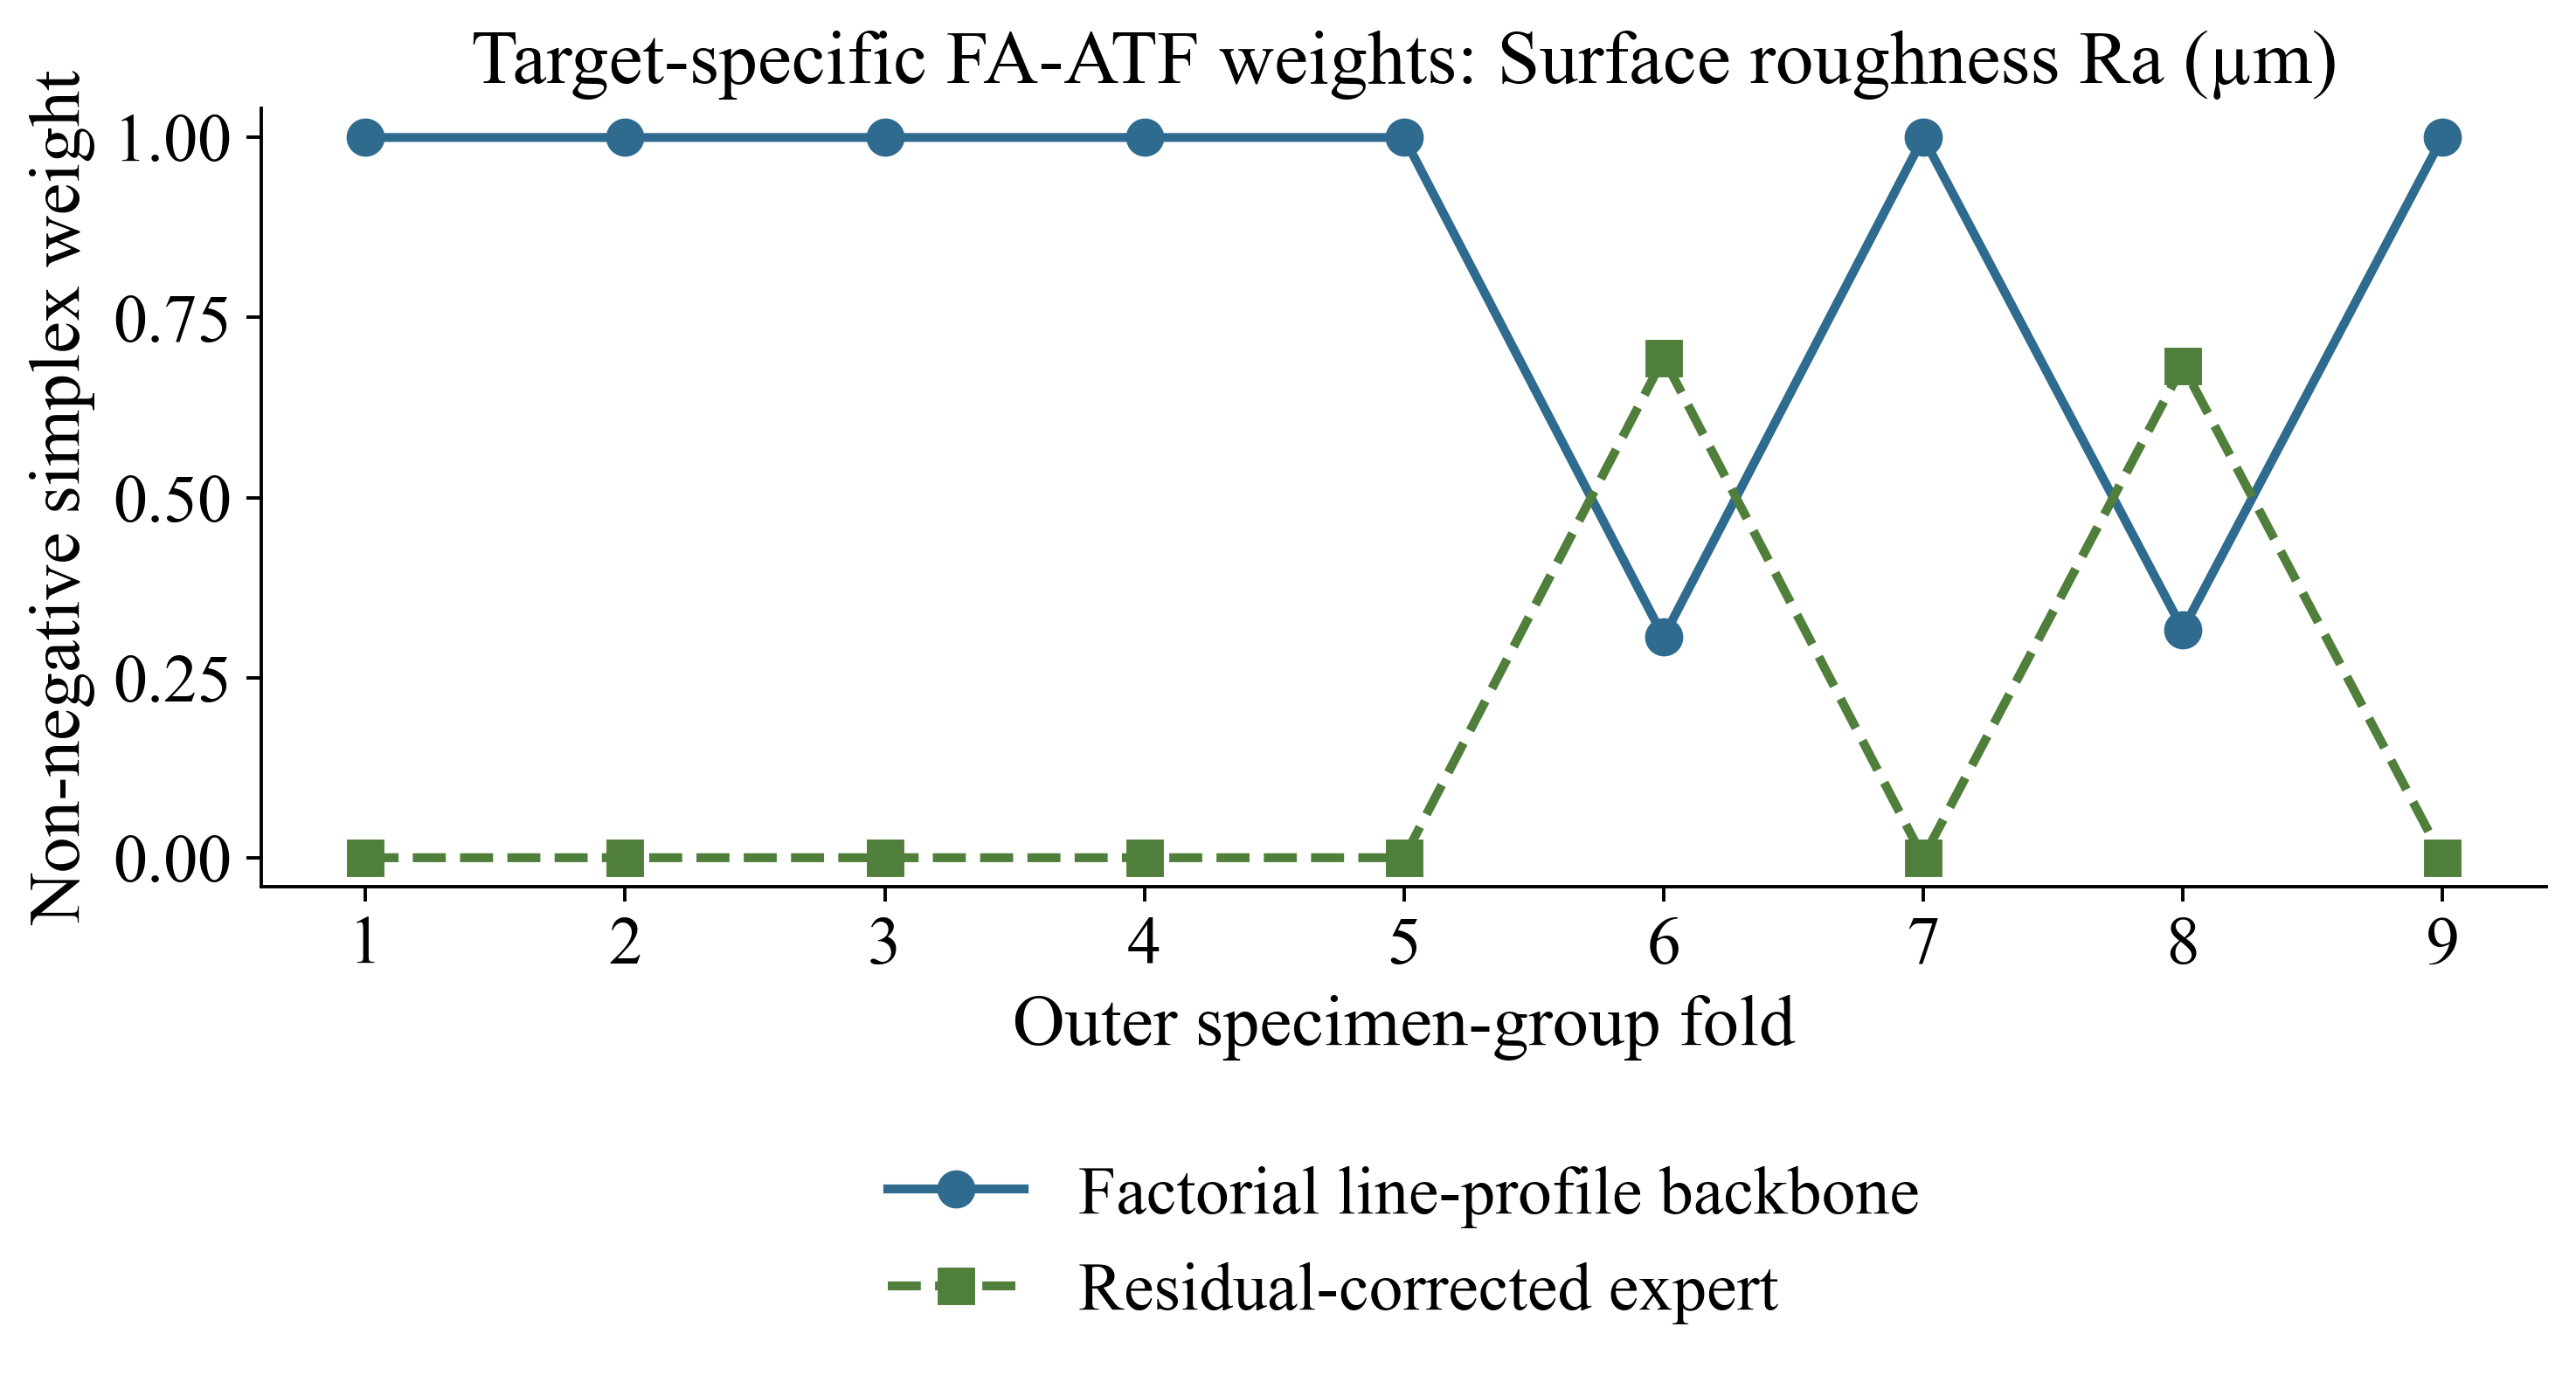

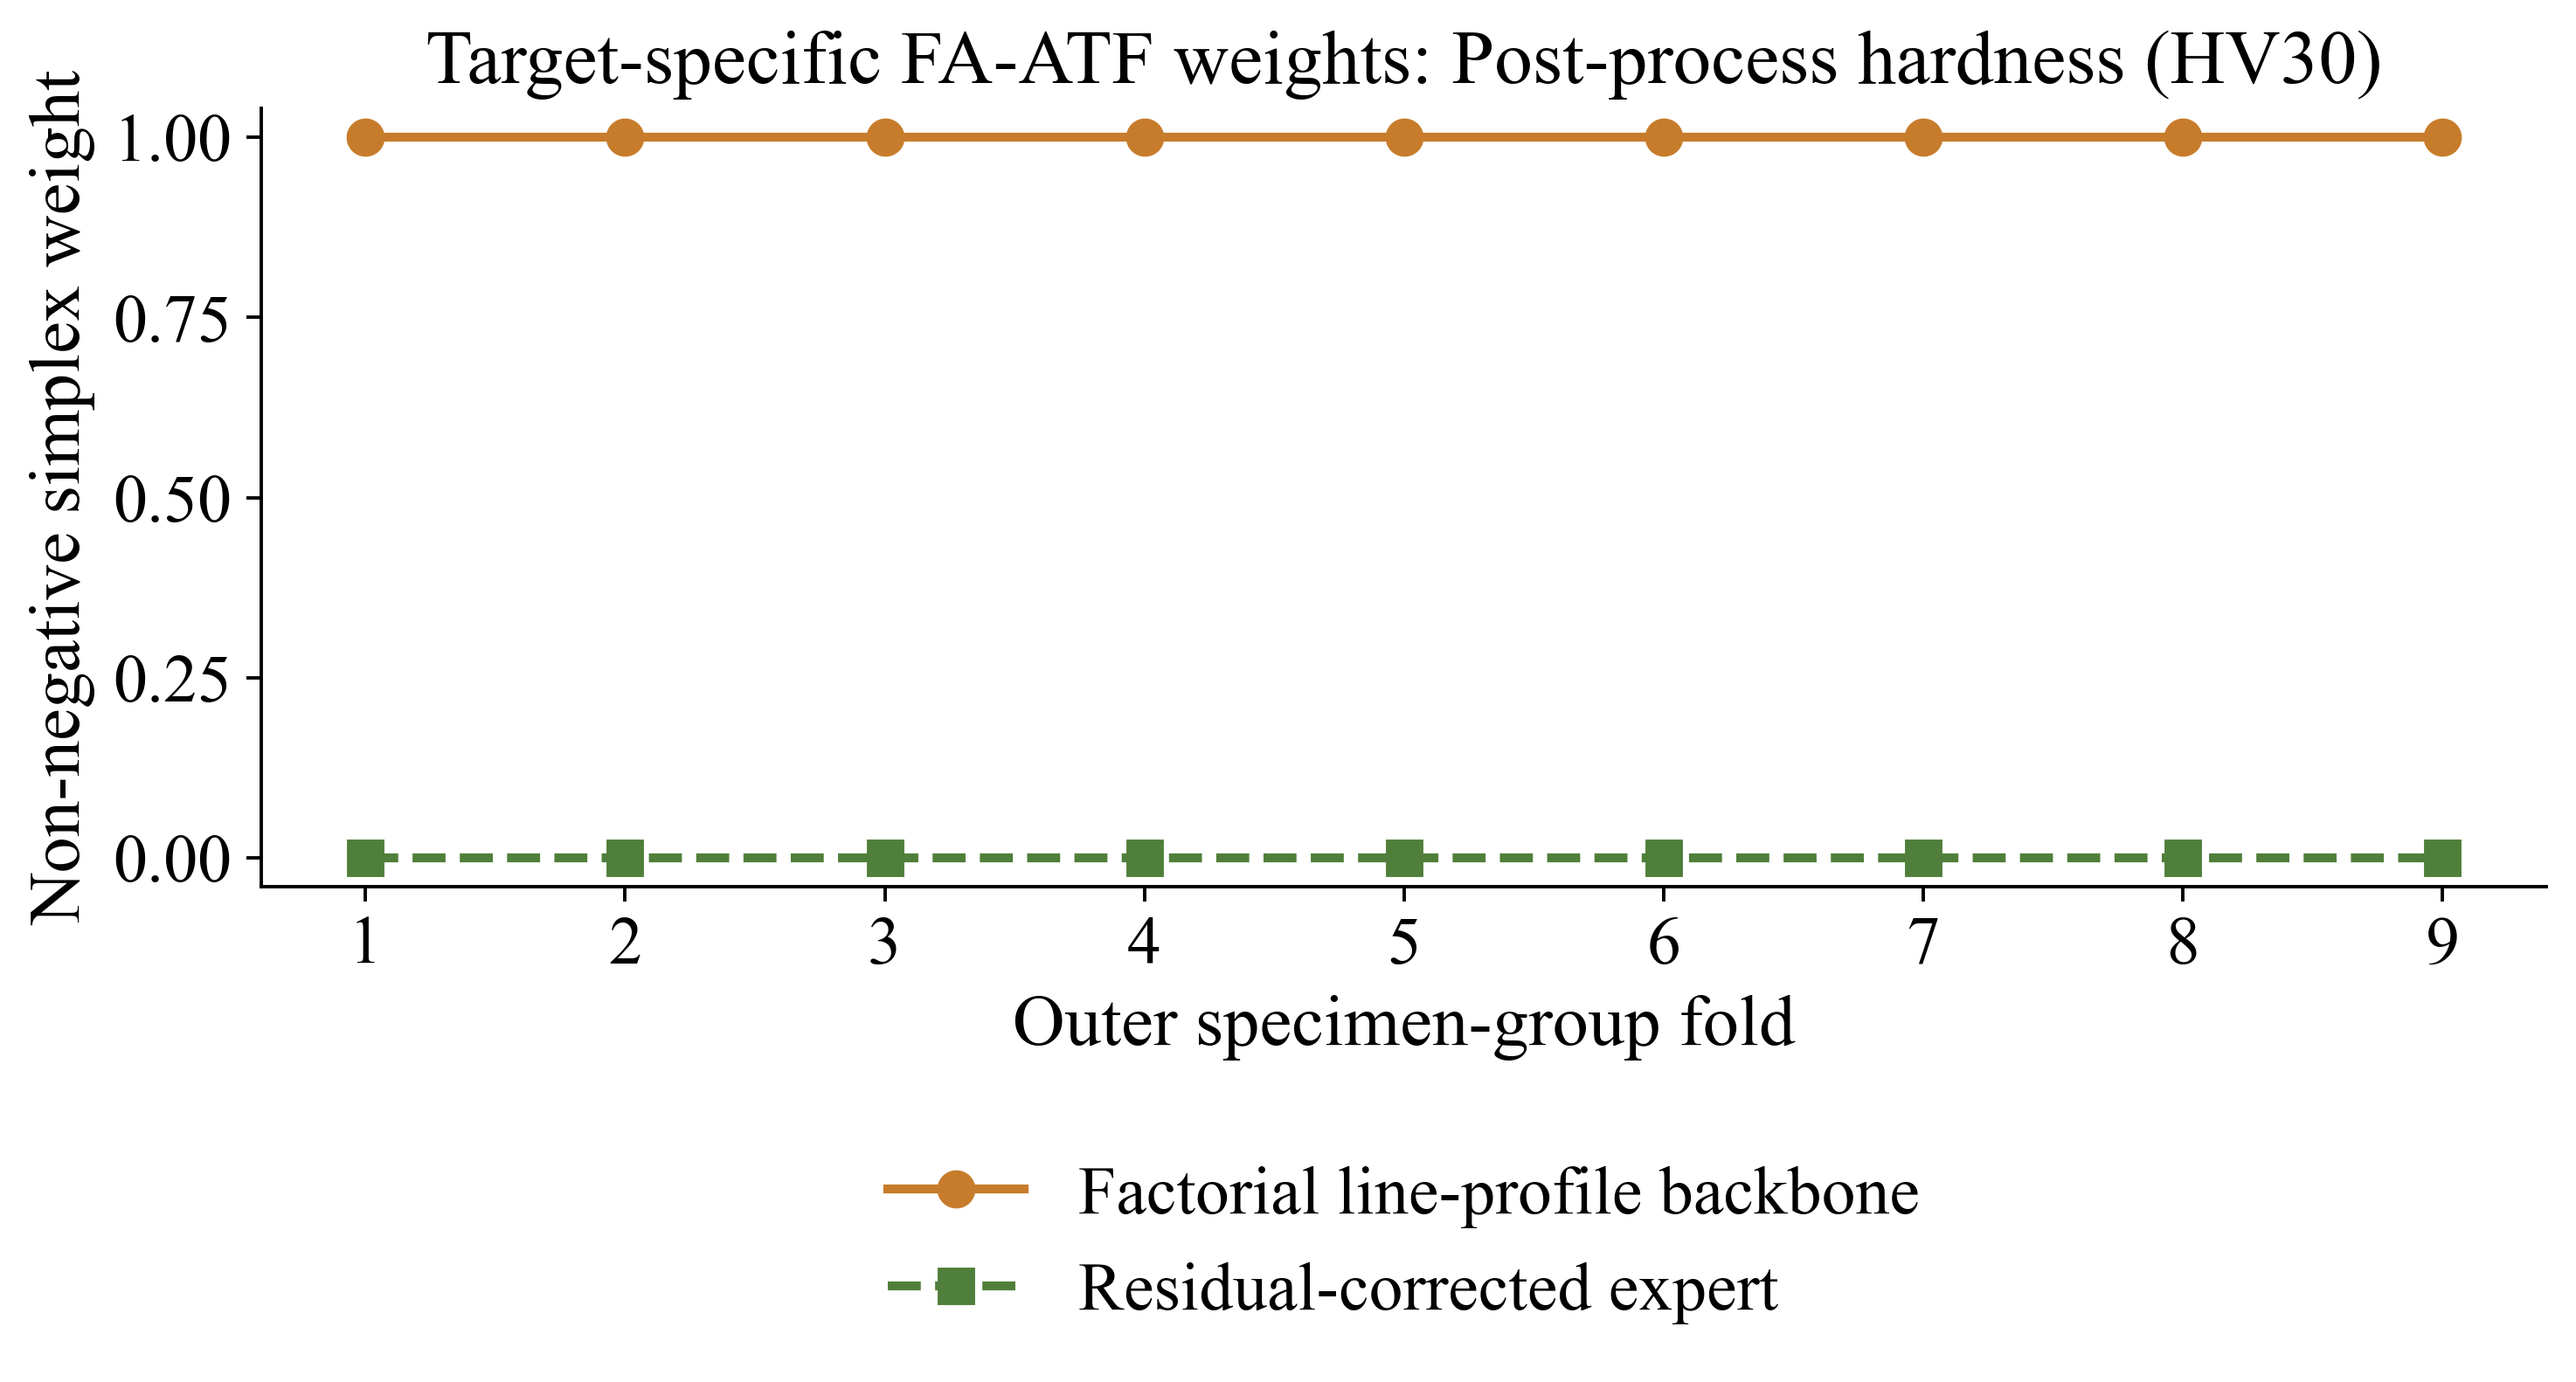

In [24]:
for target, slug, color in [
    (TARGETS[0], 'ra', PALETTE['blue']),
    (TARGETS[1], 'hv30', PALETTE['orange']),
]:
    part = weight_table[weight_table.target.eq(target)].copy()
    fig, axis = plt.subplots(figsize=(9.0, 5.3))
    styles = [
        ('Factorial line-profile backbone', color, 'o', '-'),
        ('Residual-corrected expert', PALETTE['green'], 's', '--'),
    ]
    for expert, line_color, marker, linestyle in styles:
        series = part[part.expert.eq(expert)].sort_values('outer_fold')
        axis.plot(
            series.outer_fold, series.weight, label=expert,
            color=line_color, marker=marker, linestyle=linestyle,
            linewidth=2.1, markersize=8,
        )
    axis.set_title(f"Target-specific FA-ATF weights: {TARGET_LABELS[target]}")
    axis.set_xlabel('Outer specimen-group fold')
    axis.set_ylabel('Non-negative simplex weight')
    axis.set_xticks(range(1, 10))
    axis.set_ylim(-0.04, 1.04)
    axis.grid(axis='both')
    axis.legend(
        loc='upper center', bbox_to_anchor=(0.5, -0.28),
        ncol=1, frameon=False,
    )
    fig.subplots_adjust(left=0.15, right=0.98, top=0.84, bottom=0.36)
    save_scientific_figure(
        fig, f'fa_atf_minimal_target_weights_{slug}', part
    )
    display(fig)
    plt.close(fig)


## 10. Final OOF accuracy and uncertainty


In [25]:
all_ablation_predictions = pd.DataFrame(prediction_rows)
if int(retained_counts.global_retained) == 0:
    all_ablation_predictions = all_ablation_predictions[
        all_ablation_predictions.variant.ne('Without global nonlinear branch')
    ].copy()
if int(retained_counts.neural_retained) == 0:
    all_ablation_predictions = all_ablation_predictions[
        all_ablation_predictions.variant.ne('Without compact neural branch')
    ].copy()
fa_predictions = all_ablation_predictions[
    all_ablation_predictions.variant.eq('Full FA-ATF')
].copy()
fa_predictions['model'] = 'FA-ATF'
fa_predictions['model_family'] = 'Proposed'
fa_predictions = fa_predictions[
    ['sample_id', 'specimen_id', 'section_id', 'outer_fold',
     'model', 'model_family', 'target', 'y_true', 'y_pred']
]
fa_ablations = all_ablation_predictions.copy()
fa_uncertainty = pd.DataFrame(uncertainty_rows)
expert_outer_predictions = pd.DataFrame(expert_rows)

assert fa_predictions.groupby('target').sample_id.nunique().eq(81).all()
ablation_coverage = fa_ablations.groupby(
    ['variant', 'target']
).sample_id.nunique().rename('n_samples').reset_index()
display_grouped_table(ablation_coverage, "Controlled ablation coverage")
assert ablation_coverage.n_samples.eq(81).all()

fa_predictions.to_csv(PREDICTION_DIR / 'fa_atf_oof_predictions.csv', index=False)
fa_ablations.to_csv(
    PREDICTION_DIR / 'fa_atf_ablation_oof_predictions.csv', index=False
)
fa_uncertainty.to_csv(
    PREDICTION_DIR / 'fa_atf_uncertainty_oof.csv', index=False
)
expert_outer_predictions.to_csv(
    PREDICTION_DIR / 'fa_atf_expert_outer_oof.csv', index=False
)


**Controlled ablation coverage — target=post_process_hardness_HV30 — Complete table**

target,variant,n_samples
post_process_hardness_HV30,Full FA-ATF,81
post_process_hardness_HV30,Shared weights across targets,81
post_process_hardness_HV30,Strongest single branch only,81
post_process_hardness_HV30,Uniform fusion,81
post_process_hardness_HV30,Without factorial line-profile branch,81
post_process_hardness_HV30,Without physics-guided/meta features,81
post_process_hardness_HV30,Without residual correction,81


**Controlled ablation coverage — target=surface_roughness_Ra_um — Complete table**

target,variant,n_samples
surface_roughness_Ra_um,Full FA-ATF,81
surface_roughness_Ra_um,Shared weights across targets,81
surface_roughness_Ra_um,Strongest single branch only,81
surface_roughness_Ra_um,Uniform fusion,81
surface_roughness_Ra_um,Without factorial line-profile branch,81
surface_roughness_Ra_um,Without physics-guided/meta features,81
surface_roughness_Ra_um,Without residual correction,81


In [26]:
def metrics_from_predictions(predictions, model_column):
    rows = []
    for (model_name, target), part in predictions.groupby(
        [model_column, 'target']
    ):
        y_true = part.y_true.to_numpy()
        y_pred = part.y_pred.to_numpy()
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        rows.append({
            model_column: model_name, 'target': target,
            'n': len(part),
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': rmse, 'R2': r2_score(y_true, y_pred),
            'NRMSE': rmse / np.std(y_true, ddof=1),
        })
    return pd.DataFrame(rows)

fa_metrics = metrics_from_predictions(fa_predictions, 'model')
ablation_target_metrics = metrics_from_predictions(fa_ablations, 'variant')
ablation_summary = ablation_target_metrics.groupby('variant', as_index=False).agg(
    mean_target_NRMSE=('NRMSE', 'mean'),
    macro_R2=('R2', 'mean'),
)
fa_metrics.to_csv(METRIC_DIR / 'fa_atf_target_metrics.csv', index=False)
ablation_summary.to_csv(
    METRIC_DIR / 'fa_atf_ablation_summary.csv', index=False
)
ablation_target_metrics.to_csv(
    METRIC_DIR / 'fa_atf_ablation_target_metrics.csv', index=False
)
display_grouped_table(fa_metrics.round(5), 'Final FA-ATF target-wise OOF metrics')
display_grouped_table(
    ablation_summary.sort_values('mean_target_NRMSE').round(5),
    'Dimensionless ablation ranking',
)


**Final FA-ATF target-wise OOF metrics — Complete table**

model,target,n,MAE,RMSE,R2,NRMSE
FA-ATF,post_process_hardness_HV30,81,12.340110,15.358470,0.885270,0.336620
FA-ATF,surface_roughness_Ra_um,81,0.219110,0.356350,0.823130,0.417950


**Dimensionless ablation ranking — Complete table**

variant,mean_target_NRMSE,macro_R2
Full FA-ATF,0.377290,0.854200
Shared weights across targets,0.377300,0.854190
Uniform fusion,0.377350,0.854150
Strongest single branch only,0.377550,0.853970
Without residual correction,0.378250,0.853380
Without physics-guided/meta features,0.378480,0.853190
Without factorial line-profile branch,0.470920,0.756520


In [27]:
uncertainty_summary = fa_uncertainty.groupby('target', as_index=False).apply(
    lambda part: pd.Series({
        'n': len(part),
        'empirical_coverage': np.mean(
            (part.y_true >= part.lower_90)
            & (part.y_true <= part.upper_90)
        ),
        'mean_interval_width': np.mean(part.upper_90 - part.lower_90),
        'median_interval_width': np.median(part.upper_90 - part.lower_90),
        'normalized_mean_width': (
            np.mean(part.upper_90 - part.lower_90)
            / part.y_true.std(ddof=1)
        ),
        'normalized_median_width': (
            np.median(part.upper_90 - part.lower_90)
            / part.y_true.std(ddof=1)
        ),
        'mean_interval_score_90': np.mean(
            (part.upper_90 - part.lower_90)
            + 20.0 * np.maximum(part.lower_90 - part.y_true, 0.0)
            + 20.0 * np.maximum(part.y_true - part.upper_90, 0.0)
        ),
        'normalized_mean_interval_score_90': np.mean(
            (part.upper_90 - part.lower_90)
            + 20.0 * np.maximum(part.lower_90 - part.y_true, 0.0)
            + 20.0 * np.maximum(part.y_true - part.upper_90, 0.0)
        ) / part.y_true.std(ddof=1),
    }), include_groups=False
).reset_index(drop=True)
uncertainty_summary.to_csv(
    METRIC_DIR / 'fa_atf_uncertainty_summary.csv', index=False
)
display_grouped_table(uncertainty_summary.round(5), "Specimen-aware interval performance")


**Specimen-aware interval performance — Predictive performance**

target,mean_interval_score_90,normalized_mean_interval_score_90
post_process_hardness_HV30,73.215880,1.604730
surface_roughness_Ra_um,3.169420,3.717310


**Specimen-aware interval performance — Uncertainty and statistical evidence**

target,empirical_coverage,mean_interval_width,median_interval_width
post_process_hardness_HV30,0.987650,73.168900,72.906910
surface_roughness_Ra_um,0.962960,2.901130,3.042960


**Specimen-aware interval performance — Sample, fold, and provenance**

target,normalized_mean_width,normalized_median_width
post_process_hardness_HV30,1.603700,1.597960
surface_roughness_Ra_um,3.402650,3.568990


**Specimen-aware interval performance — Additional reported attributes**

target,n
post_process_hardness_HV30,81.000000
surface_roughness_Ra_um,81.000000


The nominal 90% intervals use finite-sample higher quantiles of specimen-level maximum absolute residuals from the selected group-cross-fitted inner predictions. This specimen-aware score avoids treating the three depth sections of one profile as independent calibration units. The intervals are leakage-safe for the outer fold, but they are not independent split-conformal intervals because the same training-side OOF evidence also selects the residual configuration; coverage and width are therefore descriptive rather than an exact finite-sample guarantee.


## 11. Paired bootstrap and fold-level ablation statistics


In [28]:
target_scales = data[TARGETS].std(ddof=1).to_dict()
fold_metric_rows = []
for (variant, outer_fold, target), part in fa_ablations.groupby(
    ['variant', 'outer_fold', 'target']
):
    rmse = np.sqrt(mean_squared_error(part.y_true, part.y_pred))
    fold_metric_rows.append({
        'variant': variant, 'outer_fold': int(outer_fold),
        'target': target, 'NRMSE': rmse / target_scales[target],
    })
fold_target_metrics = pd.DataFrame(fold_metric_rows)
fold_macro = fold_target_metrics.groupby(
    ['variant', 'outer_fold'], as_index=False
).NRMSE.mean().rename(columns={'NRMSE': 'mean_target_NRMSE'})
full_fold = fold_macro[
    fold_macro.variant.eq('Full FA-ATF')
][['outer_fold', 'mean_target_NRMSE']].rename(
    columns={'mean_target_NRMSE': 'full_NRMSE'}
)
fold_differences = fold_macro.merge(full_fold, on='outer_fold')
fold_differences['delta_vs_full'] = (
    fold_differences.mean_target_NRMSE - fold_differences.full_NRMSE
)


In [29]:
sample_order = np.sort(data.sample_id.unique())
group_by_sample = data.set_index('sample_id').loc[
    sample_order, 'specimen_id'
].to_numpy()
unique_groups = np.unique(group_by_sample)
positions_by_group = {
    group: np.flatnonzero(group_by_sample == group)
    for group in unique_groups
}
bootstrap_rng = np.random.default_rng(SEED + 911)
bootstrap_positions = [
    np.concatenate([
        positions_by_group[group]
        for group in bootstrap_rng.choice(
            unique_groups, size=len(unique_groups), replace=True
        )
    ])
    for _ in range(BOOTSTRAP_RESAMPLES)
]

variant_bootstrap = {}
for variant, variant_part in fa_ablations.groupby('variant'):
    target_values = []
    for target in TARGETS:
        part = variant_part[variant_part.target.eq(target)]
        truth = part.groupby('sample_id').y_true.first().reindex(sample_order).to_numpy()
        prediction = part.set_index('sample_id').reindex(sample_order).y_pred.to_numpy()
        values = np.array([
            np.sqrt(np.mean(
                (truth[positions] - prediction[positions]) ** 2
            )) / target_scales[target]
            for positions in bootstrap_positions
        ])
        target_values.append(values)
    variant_bootstrap[variant] = np.mean(
        np.column_stack(target_values), axis=1
    )


In [30]:
def matched_rank_biserial(differences):
    differences = np.asarray(differences)
    nonzero = differences[np.abs(differences) > 1e-12]
    if len(nonzero) == 0:
        return 0.0
    ranks = rankdata(np.abs(nonzero))
    return float(
        (ranks[nonzero > 0].sum() - ranks[nonzero < 0].sum())
        / ranks.sum()
    )

comparison_rows = []
full_point = ablation_summary.set_index('variant').loc[
    'Full FA-ATF', 'mean_target_NRMSE'
]
for variant in sorted(fa_ablations.variant.unique()):
    if variant == 'Full FA-ATF':
        continue
    fold_part = fold_differences[
        fold_differences.variant.eq(variant)
    ].sort_values('outer_fold')
    differences = fold_part.delta_vs_full.to_numpy()
    if np.all(np.abs(differences) <= 1e-12):
        p_value = 1.0
    else:
        p_value = float(wilcoxon(
            differences, alternative='greater', zero_method='pratt'
        ).pvalue)
    bootstrap_delta = (
        variant_bootstrap[variant]
        - variant_bootstrap['Full FA-ATF']
    )
    variant_point = ablation_summary.set_index('variant').loc[
        variant, 'mean_target_NRMSE'
    ]
    comparison_rows.append({
        'ablation': variant,
        'delta_mean_target_NRMSE': variant_point - full_point,
        'bootstrap_CI_low': np.quantile(bootstrap_delta, 0.025),
        'bootstrap_CI_high': np.quantile(bootstrap_delta, 0.975),
        'bootstrap_probability_ablation_worse': np.mean(bootstrap_delta > 0),
        'outer_folds_ablation_worse': int(np.sum(differences > 1e-12)),
        'outer_folds_ablation_better': int(np.sum(differences < -1e-12)),
        'median_fold_delta': float(np.median(differences)),
        'rank_biserial_effect': matched_rank_biserial(differences),
        'wilcoxon_one_sided_p': p_value,
    })

ablation_statistics = pd.DataFrame(comparison_rows).sort_values(
    'delta_mean_target_NRMSE', ascending=False
).reset_index(drop=True)
ordered_p = ablation_statistics.wilcoxon_one_sided_p.sort_values().index
adjusted = pd.Series(index=ablation_statistics.index, dtype=float)
running = 0.0
for rank, index in enumerate(ordered_p, start=1):
    value = min(1.0, (len(ordered_p) - rank + 1)
                * ablation_statistics.loc[index, 'wilcoxon_one_sided_p'])
    running = max(running, value)
    adjusted.loc[index] = running
ablation_statistics['holm_adjusted_p'] = adjusted

ablation_statistics.to_csv(
    STATISTICS_DIR / 'fa_atf_ablation_statistical_comparisons.csv', index=False
)
fold_differences.to_csv(
    STATISTICS_DIR / 'fa_atf_ablation_fold_directions.csv', index=False
)
display_grouped_table(ablation_statistics.round(5), "Paired full-model versus ablation statistics")


**Paired full-model versus ablation statistics — Predictive performance**

ablation,delta_mean_target_NRMSE,rank_biserial_effect
Without factorial line-profile branch,0.093630,0.644440
Without physics-guided/meta features,0.001190,1.000000
Without residual correction,0.000960,-0.333330
Strongest single branch only,0.000270,0.333330
Uniform fusion,0.000060,-0.333330
Shared weights across targets,0.000010,-0.333330


**Paired full-model versus ablation statistics — Uncertainty and statistical evidence (part 1/2)**

ablation,bootstrap_CI_low,bootstrap_CI_high,bootstrap_probability_ablation_worse,median_fold_delta,wilcoxon_one_sided_p
Without factorial line-profile branch,0.000560,0.168910,0.975500,0.028750,0.048830
Without physics-guided/meta features,-0.000490,0.003960,0.910000,0.000000,0.250000
Without residual correction,-0.006040,0.009280,0.599500,0.000000,0.750000
Strongest single branch only,-0.002840,0.003570,0.608500,0.000000,0.500000
Uniform fusion,-0.001960,0.002180,0.523000,0.000000,0.750000
Shared weights across targets,-0.000620,0.000650,0.497500,0.000000,0.750000


**Paired full-model versus ablation statistics — Uncertainty and statistical evidence (part 2/2)**

ablation,holm_adjusted_p
Without factorial line-profile branch,0.292970
Without physics-guided/meta features,1.000000
Without residual correction,1.000000
Strongest single branch only,1.000000
Uniform fusion,1.000000
Shared weights across targets,1.000000


**Paired full-model versus ablation statistics — Sample, fold, and provenance**

ablation,outer_folds_ablation_worse,outer_folds_ablation_better
Without factorial line-profile branch,7,2
Without physics-guided/meta features,2,0
Without residual correction,1,1
Strongest single branch only,1,1
Uniform fusion,1,1
Shared weights across targets,1,1


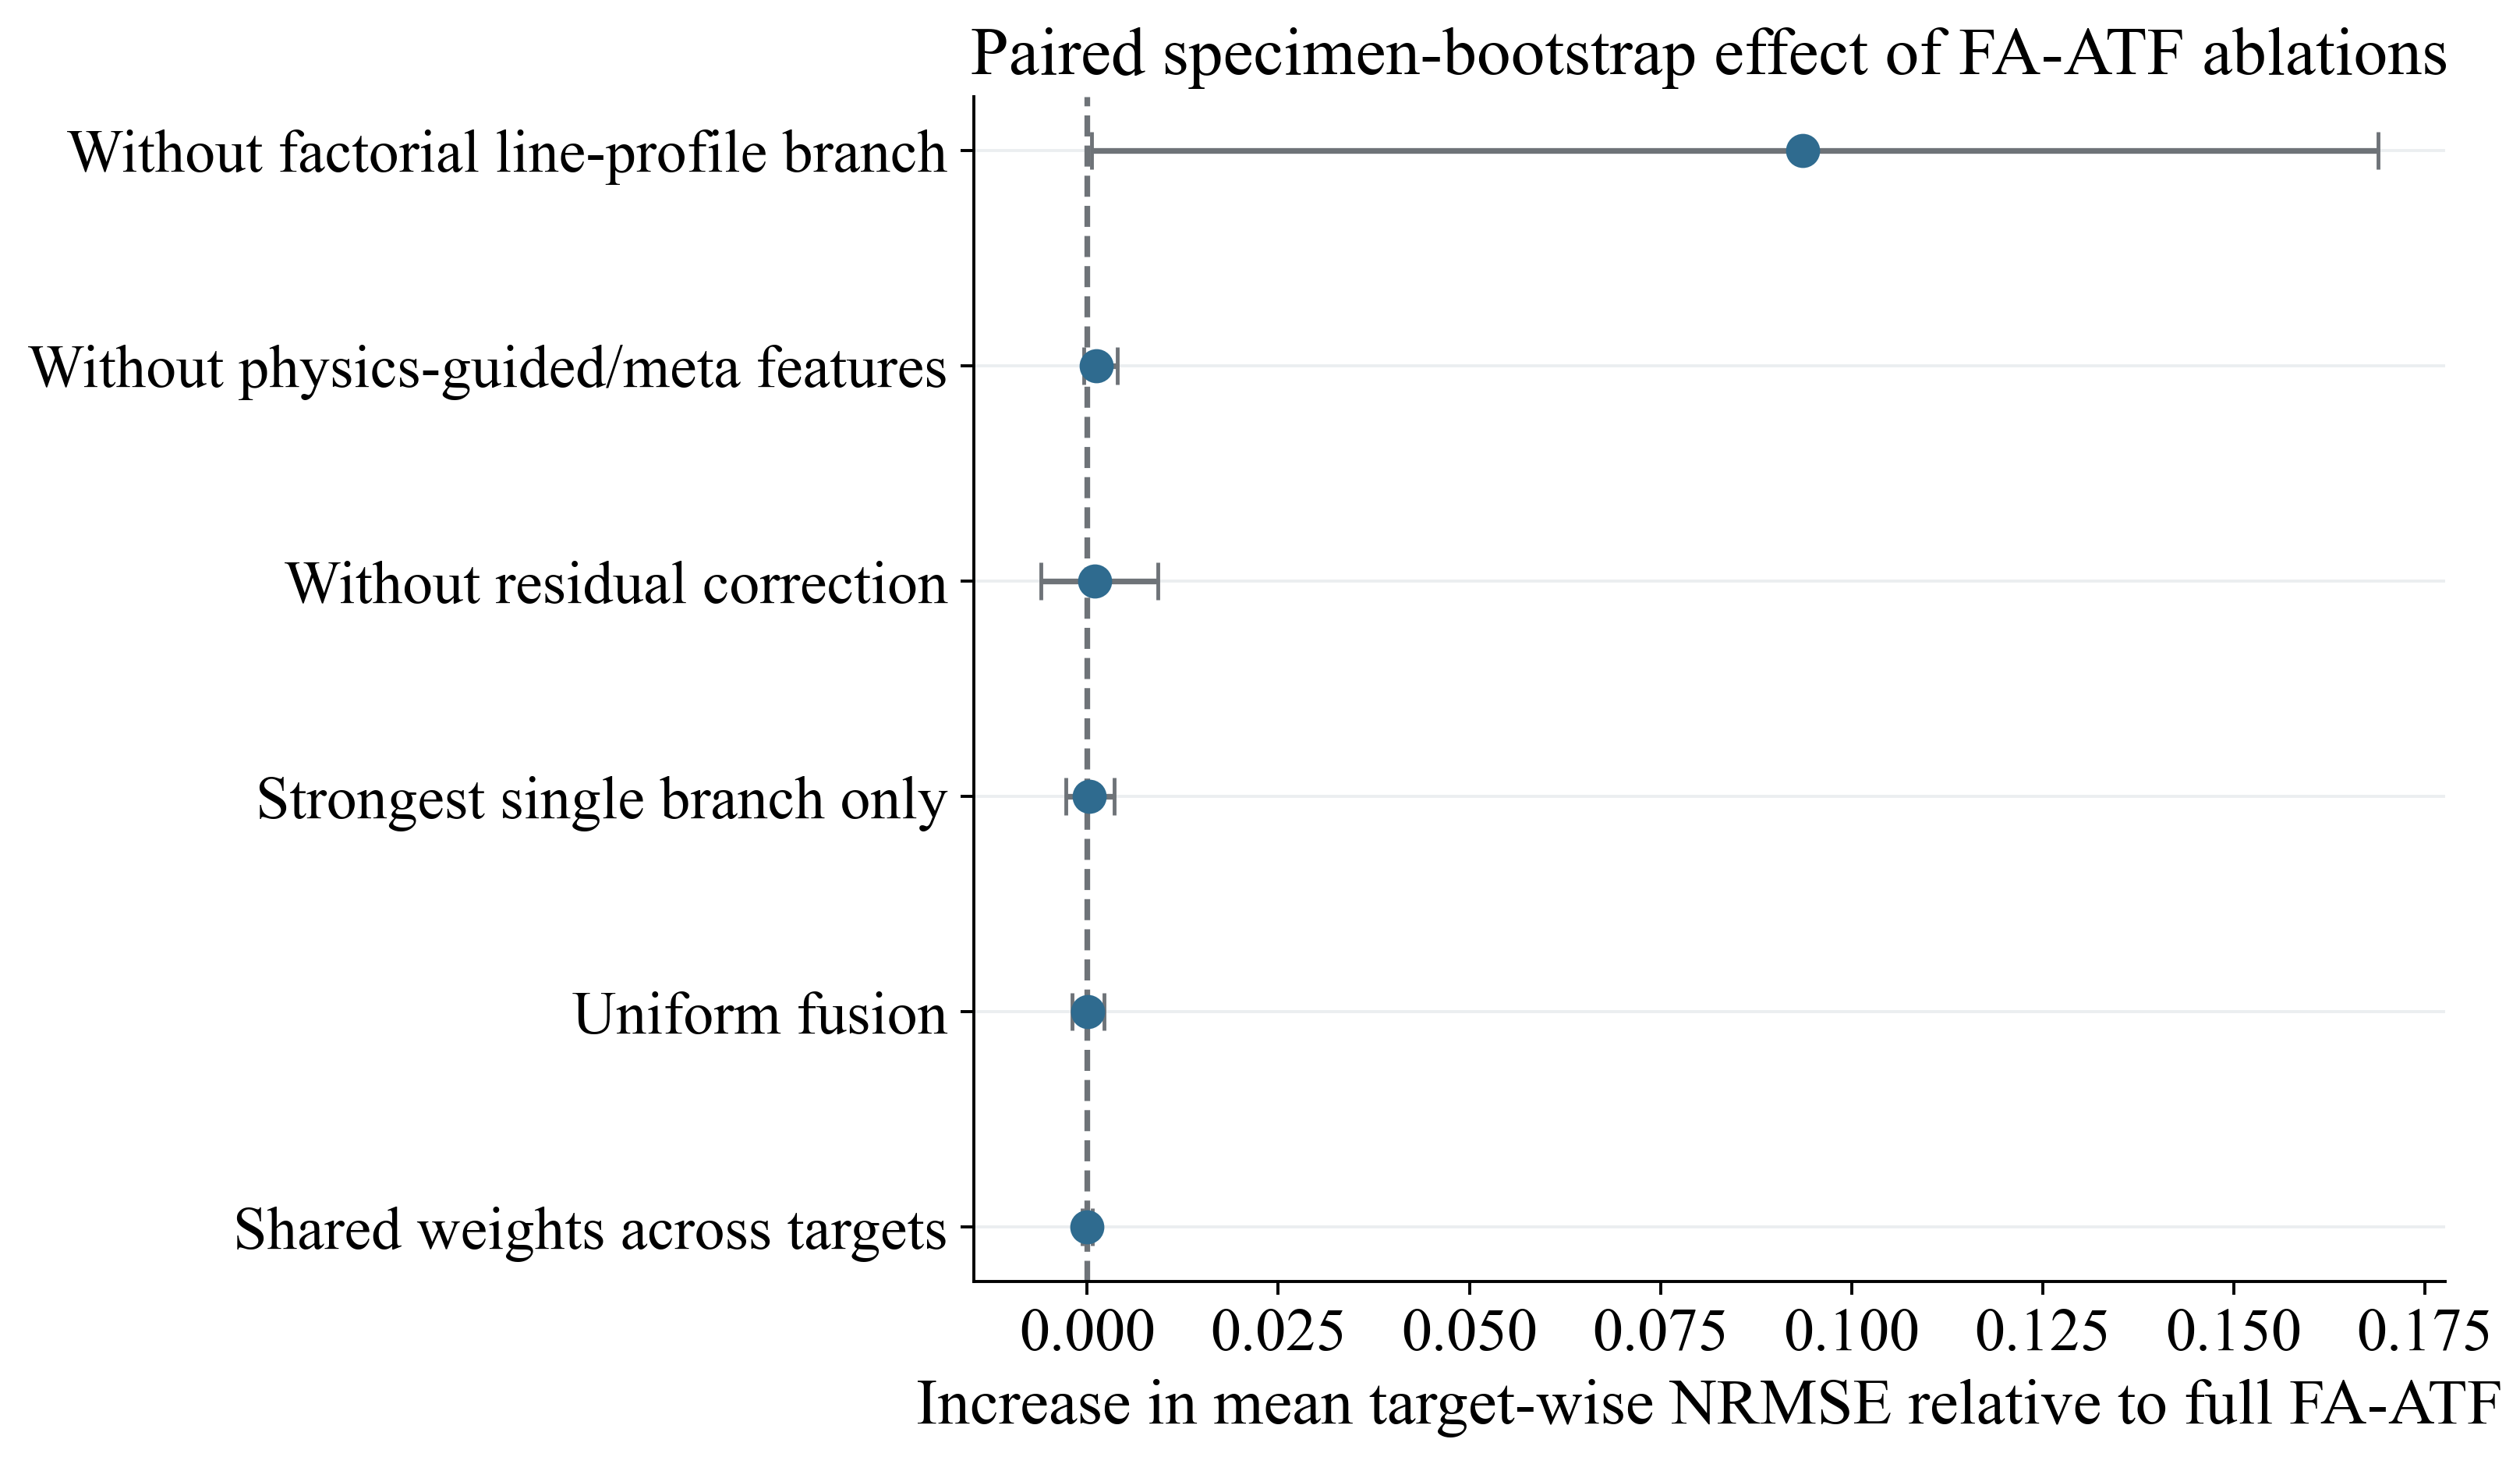

In [31]:
plot_part = ablation_statistics.sort_values(
    'delta_mean_target_NRMSE', ascending=True
)
positions = np.arange(len(plot_part))
lower = plot_part.delta_mean_target_NRMSE - plot_part.bootstrap_CI_low
upper = plot_part.bootstrap_CI_high - plot_part.delta_mean_target_NRMSE
fig, axis = plt.subplots(figsize=(9.8, 6.2))
axis.errorbar(
    plot_part.delta_mean_target_NRMSE, positions,
    xerr=np.vstack([lower, upper]), fmt='o', markersize=8,
    color=PALETTE['blue'], ecolor=PALETTE['gray'], capsize=5,
)
axis.axvline(0.0, linestyle='--', color=PALETTE['gray'])
axis.set_yticks(positions, labels=plot_part.ablation)
axis.set_title('Paired specimen-bootstrap effect of FA-ATF ablations')
axis.set_xlabel('Increase in mean target-wise NRMSE relative to full FA-ATF')
axis.set_ylabel('')
axis.grid(axis='x')
fig.subplots_adjust(left=0.43, right=0.98, top=0.88, bottom=0.18)
save_scientific_figure(
    fig, 'fa_atf_minimal_ablation_bootstrap', ablation_statistics
)
display(fig)
plt.close(fig)


## 12. Fold-level stability and computational profile


**FA-ATF outer-fold stability — Complete table**

target,outer_folds,mean_fold_NRMSE,SD_fold_NRMSE,min_fold_NRMSE,max_fold_NRMSE
post_process_hardness_HV30,9,0.327370,0.083150,0.214340,0.453760
surface_roughness_Ra_um,9,0.334070,0.266390,0.074180,0.861040


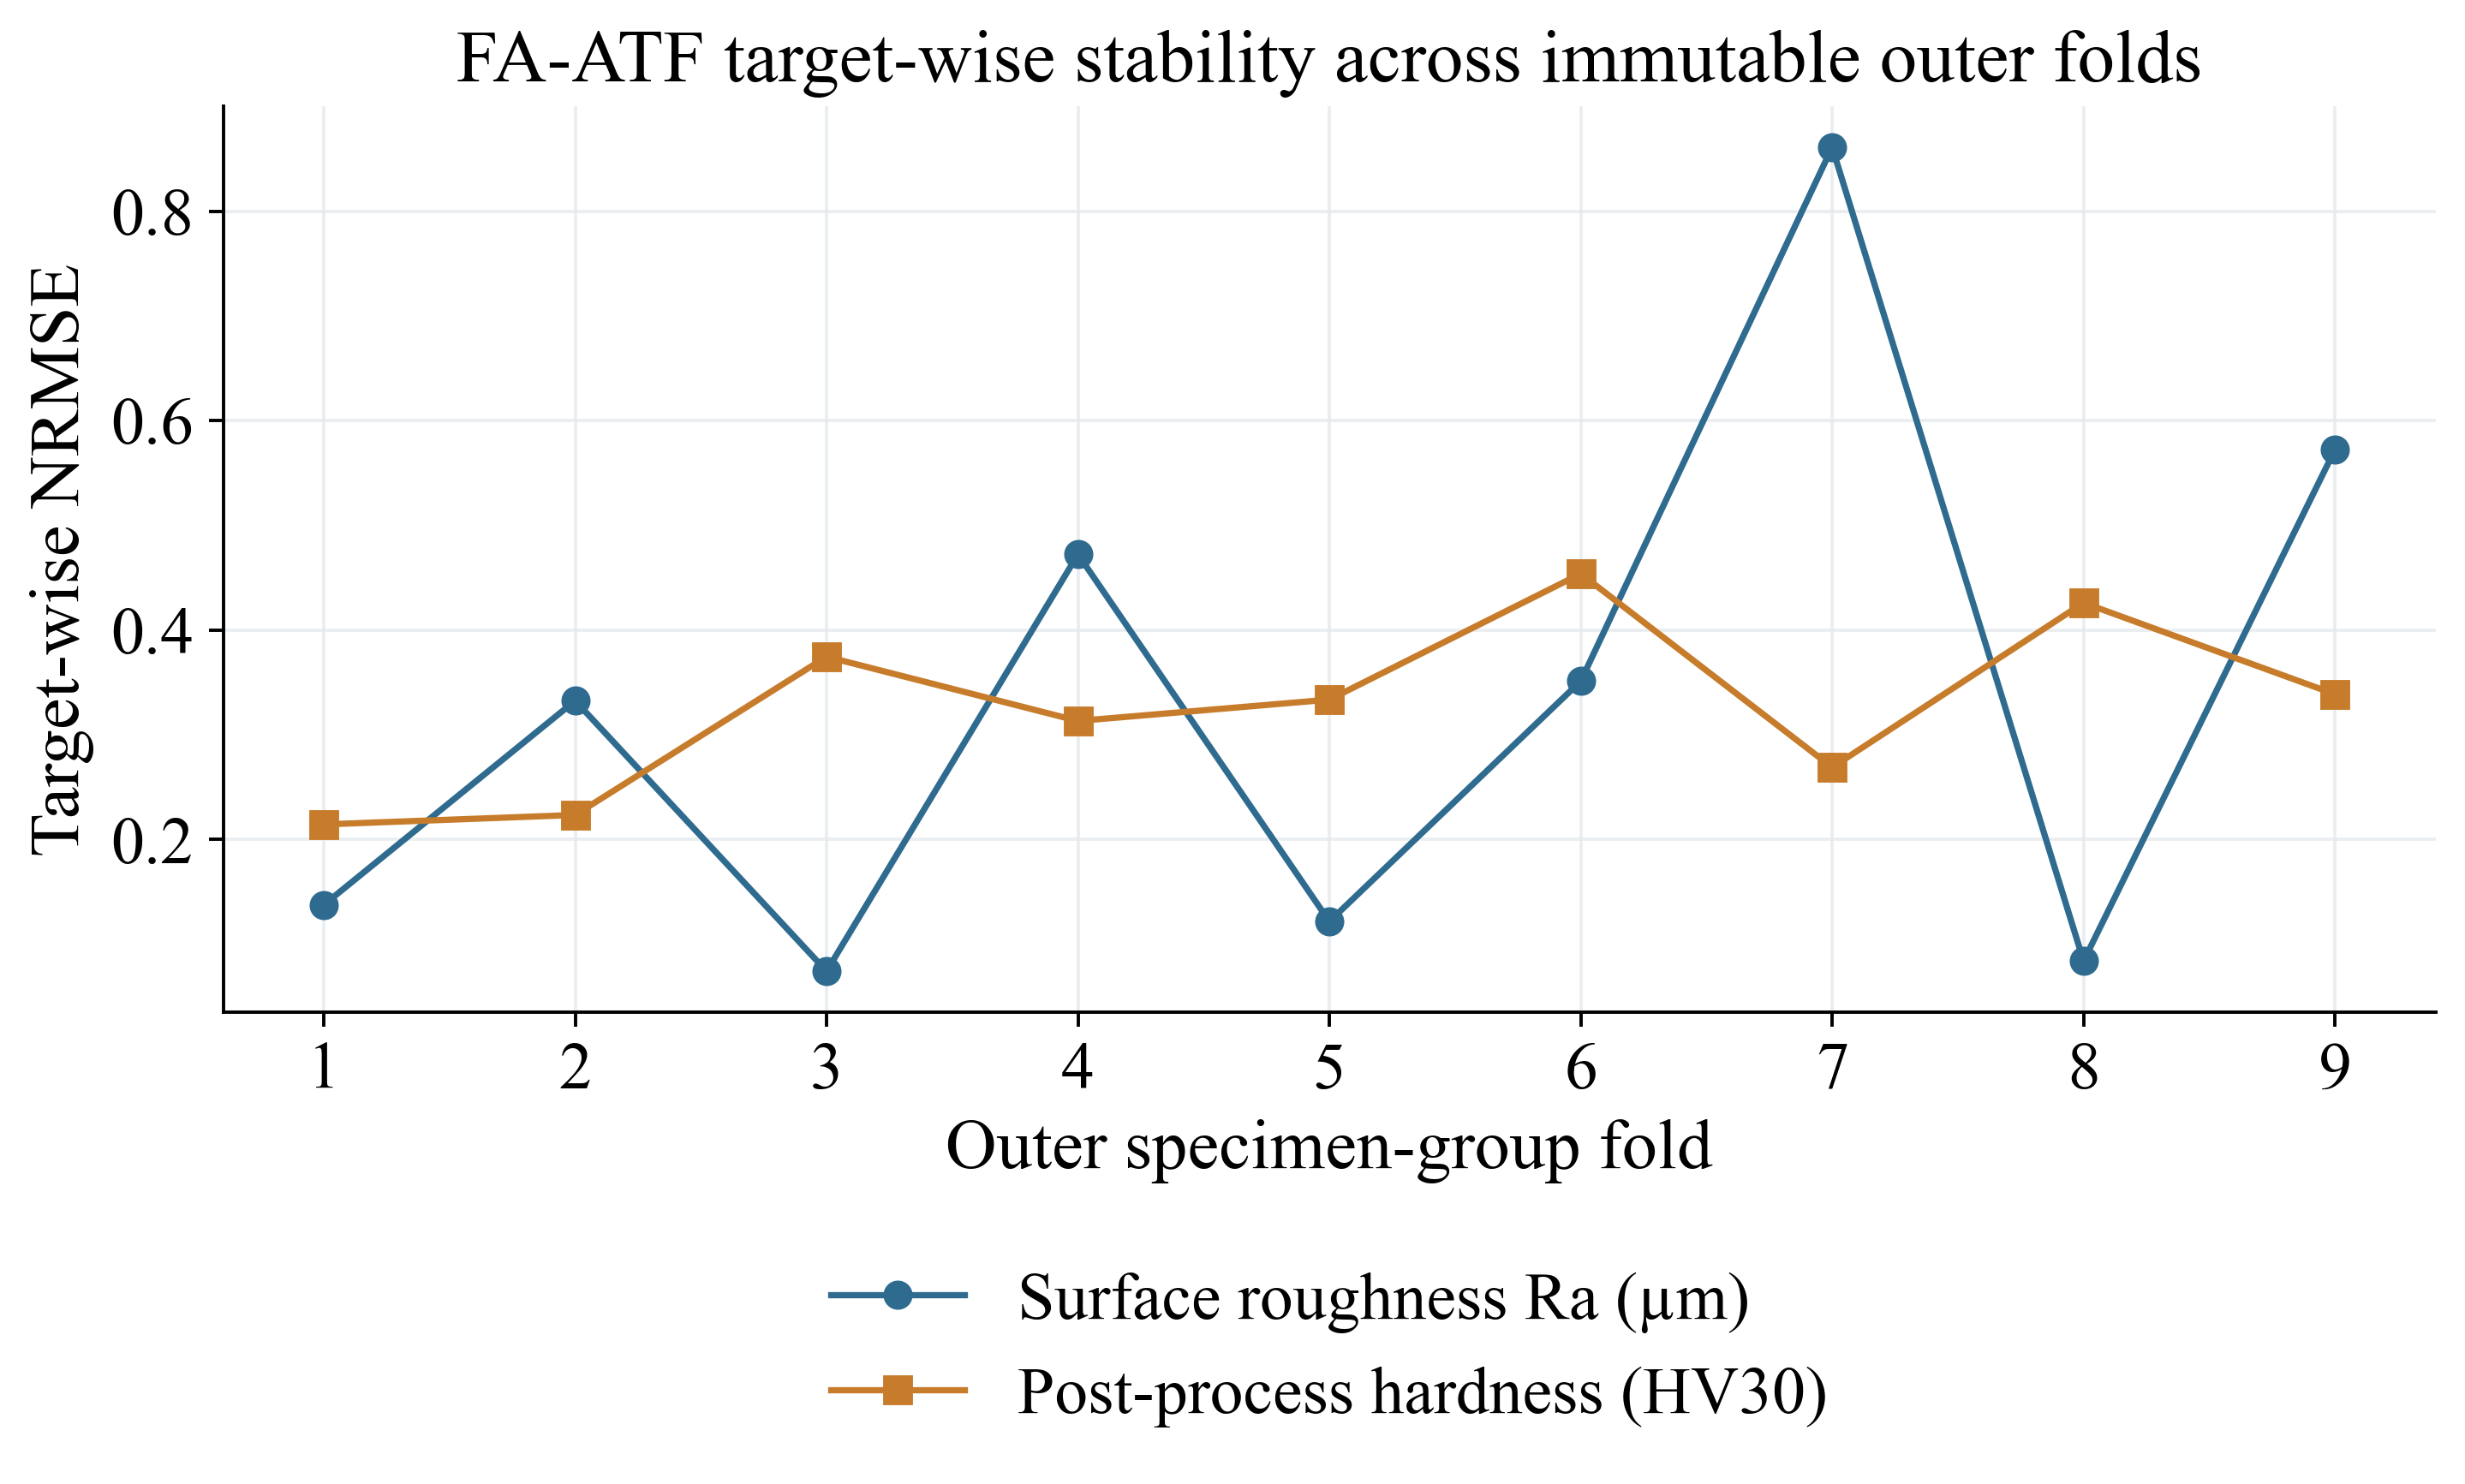

In [32]:
full_fold_target = fold_target_metrics[
    fold_target_metrics.variant.eq('Full FA-ATF')
].copy()
stability_summary = full_fold_target.groupby('target', as_index=False).agg(
    outer_folds=('outer_fold', 'nunique'),
    mean_fold_NRMSE=('NRMSE', 'mean'),
    SD_fold_NRMSE=('NRMSE', 'std'),
    min_fold_NRMSE=('NRMSE', 'min'),
    max_fold_NRMSE=('NRMSE', 'max'),
)
stability_summary.to_csv(
    METRIC_DIR / 'fa_atf_fold_stability_summary.csv', index=False
)
display_grouped_table(stability_summary.round(5), "FA-ATF outer-fold stability")

fig, axis = plt.subplots(figsize=(9.0, 5.4))
for target, color, marker in [
    (TARGETS[0], PALETTE['blue'], 'o'),
    (TARGETS[1], PALETTE['orange'], 's'),
]:
    part = full_fold_target[full_fold_target.target.eq(target)]
    axis.plot(
        part.outer_fold, part.NRMSE, marker=marker, color=color,
        label=TARGET_LABELS[target],
    )
axis.set_title('FA-ATF target-wise stability across immutable outer folds')
axis.set_xlabel('Outer specimen-group fold')
axis.set_ylabel('Target-wise NRMSE')
axis.set_xticks(sorted(data.outer_fold.unique()))
axis.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=1,
            frameon=False)
fig.subplots_adjust(left=0.16, right=0.98, top=0.88, bottom=0.32)
save_scientific_figure(
    fig, 'fa_atf_minimal_fold_stability', full_fold_target
)
display(fig)
plt.close(fig)


In [33]:
def predict_runtime_bundle(bundle, frame):
    predictions = {}
    neural_prediction = (
        predict_neural_records(bundle['neural_records'], frame)
        if bundle['neural_records'] else None
    )
    for target_index, target in enumerate(TARGETS):
        selection = bundle['selections'][target]
        runtime = bundle['contexts'][target]
        line_prediction = predict_line_profile_model(
            runtime['line_bundle'], frame
        )
        experts = [line_prediction]
        if selection['global_retained']:
            experts.append(runtime['global_model'].predict(frame[FEATURES]))
        if selection['neural_retained']:
            experts.append(neural_prediction[:, target_index])
        expert_matrix = np.column_stack(experts)
        base_prediction = expert_matrix @ selection['base_weights']
        if selection['residual_retained']:
            meta = residual_meta_features(
                frame, expert_matrix, base_prediction, include_physics=True
            )
            corrected = base_prediction + runtime['residual_model'].predict(meta)
            expert_matrix = np.column_stack([expert_matrix, corrected])
        predictions[target] = expert_matrix @ selection['final_weights']
    return predictions

timing_table = pd.DataFrame(timing_rows)
latency_rows = []
for bundle in runtime_bundles:
    fold_frame = data[data.outer_fold.eq(bundle['outer_fold'])].reset_index(drop=True)
    predict_runtime_bundle(bundle, fold_frame)
    repetitions = 30
    start = time.perf_counter()
    for _ in range(repetitions):
        prediction = predict_runtime_bundle(bundle, fold_frame)
    elapsed = (time.perf_counter() - start) / repetitions
    assert all(np.isfinite(values).all() for values in prediction.values())
    latency_rows.append({
        'outer_fold': bundle['outer_fold'],
        'inference_ms_per_sample': 1000.0 * elapsed / len(fold_frame),
    })
timing_table = timing_table.merge(
    pd.DataFrame(latency_rows), on='outer_fold', how='left'
)
bundle_path = MODEL_DIR / 'fa_atf_outer_fold_bundles.joblib'
joblib.dump(runtime_bundles, bundle_path, compress=3)
timing_table['serialized_bundle_bytes_total'] = bundle_path.stat().st_size
timing_table.to_csv(METRIC_DIR / 'fa_atf_timing.csv', index=False)

efficiency_summary = pd.DataFrame([{
    'outer folds': timing_table.outer_fold.nunique(),
    'mean fit time (s/fold)': timing_table.fit_seconds.mean(),
    'mean inference (ms/sample)': timing_table.inference_ms_per_sample.mean(),
    'residual-active target-folds': int(
        timing_table.residual_targets_retained.sum()
    ),
    'serialized bundle size (MB)': bundle_path.stat().st_size / 1024 ** 2,
}])
display_grouped_table(efficiency_summary.round(5), "FA-ATF timing and complexity")


**FA-ATF timing and complexity — Complete table**

outer folds,mean fit time (s/fold),mean inference (ms/sample),residual-active target-folds,serialized bundle size (MB)
9,7.465790,0.681290,2,0.059540


## 13. Sensitivity to alternative specimen-group fold assignments

Five additional fold-assignment seeds are pre-specified as a robustness analysis after the canonical architecture rule is frozen. Each alternative preserves one specimen from every initial-hardness level in each outer fold. The analysis reruns all training-side selection within each alternative partition and compares FA-ATF with the strongest classical baseline and the design-aware mixed-effects response surface; it is not used to change the architecture, select a reported seed, or alter the fixed 0.005 gate.


In [34]:
ALTERNATIVE_SPLIT_SEEDS = tuple(SEED + offset for offset in (101, 202, 303, 404, 505))

def alternative_outer_assignment(frame, seed):
    group_table = frame[['specimen_id', 'HV_init_HV30']].drop_duplicates()
    rng = np.random.default_rng(seed)
    rows = []
    for hardness in sorted(group_table.HV_init_HV30.unique()):
        specimens = group_table.loc[
            group_table.HV_init_HV30.eq(hardness), 'specimen_id'
        ].to_numpy()
        for fold, specimen_id in enumerate(rng.permutation(specimens), start=1):
            rows.append({'specimen_id': specimen_id, 'outer_fold': fold})
    assigned = frame.drop(columns='outer_fold').merge(
        pd.DataFrame(rows), on='specimen_id', validate='many_to_one'
    )
    assert assigned.groupby('specimen_id').outer_fold.nunique().eq(1).all()
    assert assigned.groupby('outer_fold').specimen_id.nunique().eq(3).all()
    return assigned

def factorial_mixed_design(frame):
    coded = {}
    for factor in MEASURED_FEATURES:
        levels = np.sort(data[factor].unique()).astype(float)
        mapping = {float(level): code for level, code in zip(levels, (-1.0, 0.0, 1.0))}
        linear = np.array([mapping[float(value)] for value in frame[factor]], dtype=float)
        coded[factor] = (linear, np.where(linear == 0.0, -2.0, 1.0))
    columns = [np.ones(len(frame), dtype=float)]
    for factor in MEASURED_FEATURES:
        columns.extend(coded[factor])
    depth_linear, depth_quadratic = coded['depth_of_cut_mm']
    for factor in LINE_FACTORS:
        for factor_values in coded[factor]:
            for depth_values in (depth_linear, depth_quadratic):
                columns.append(factor_values * depth_values)
    return np.column_stack(columns)

def fit_predict_factorial_mixed(training_frame, test_frame, target):
    training_design = factorial_mixed_design(training_frame)
    fit = MixedLM(
        training_frame[target].to_numpy(dtype=float), training_design,
        groups=training_frame.specimen_id.astype(str).to_numpy(),
        exog_re=np.ones((len(training_frame), 1), dtype=float),
    ).fit(reml=True, method=['lbfgs', 'powell'], maxiter=2000, disp=False)
    return factorial_mixed_design(test_frame) @ np.asarray(fit.fe_params, dtype=float)

RF_SPECS = ((3, 1), (3, 2), (None, 1), (None, 2))
def fit_predict_inner_selected_rf(training_frame, test_frame, target, inner_splits, seed):
    scored = []
    for depth, leaf in RF_SPECS:
        inner_prediction = np.empty(len(training_frame), dtype=float)
        for training_index, validation_index in inner_splits:
            model = RandomForestRegressor(
                n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                max_features=1.0, random_state=seed, n_jobs=1,
            ).fit(
                training_frame.iloc[training_index][FEATURES],
                training_frame.iloc[training_index][target],
            )
            inner_prediction[validation_index] = model.predict(
                training_frame.iloc[validation_index][FEATURES]
            )
        score = np.sqrt(mean_squared_error(training_frame[target], inner_prediction)) / training_frame[target].std(ddof=1)
        scored.append((float(score), str(depth), leaf, depth))
    _, _, best_leaf, best_depth = min(scored)
    model = RandomForestRegressor(
        n_estimators=300, max_depth=best_depth, min_samples_leaf=best_leaf,
        max_features=1.0, random_state=seed, n_jobs=1,
    ).fit(training_frame[FEATURES], training_frame[target])
    return model.predict(test_frame[FEATURES])

alternative_prediction_rows = []
for split_seed in ALTERNATIVE_SPLIT_SEEDS:
    alternative_data = alternative_outer_assignment(data, split_seed)
    for outer_fold in range(1, 10):
        outer_train = alternative_data[alternative_data.outer_fold.ne(outer_fold)].reset_index(drop=True)
        outer_test = alternative_data[alternative_data.outer_fold.eq(outer_fold)].reset_index(drop=True)
        evidence = generate_training_side_evidence(outer_train, outer_fold)
        selections = {
            target: select_target_architecture(
                outer_train, outer_fold, target, evidence, []
            ) for target in TARGETS
        }
        neural_outer = None
        if any(selection['neural_retained'] for selection in selections.values()):
            neural_outer = np.mean([
                fit_compact_neural_once(
                    outer_train, outer_test,
                    SEED + outer_fold * 5000 + seed_offset,
                )[0] for seed_offset in range(NEURAL_OUTER_SEEDS)
            ], axis=0)
        for target_index, target in enumerate(TARGETS):
            neural_target = None if neural_outer is None else neural_outer[:, target_index]
            context = fit_outer_target_context(
                outer_train, outer_test, outer_fold, target, evidence,
                selections[target], neural_target,
            )
            model_predictions = {
                'FA-ATF': context['full_prediction'],
                'RandomForest': fit_predict_inner_selected_rf(
                    outer_train, outer_test, target, evidence['splits'],
                    SEED + outer_fold,
                ),
                'HierarchicalMixedEffects': fit_predict_factorial_mixed(
                    outer_train, outer_test, target
                ),
            }
            for model_name, prediction in model_predictions.items():
                for row_index, row in outer_test.iterrows():
                    alternative_prediction_rows.append({
                        'split_seed': split_seed, 'outer_fold': outer_fold,
                        'sample_id': int(row.sample_id), 'specimen_id': row.specimen_id,
                        'model': model_name, 'target': target,
                        'y_true': float(row[target]), 'y_pred': float(prediction[row_index]),
                    })

alternative_predictions = pd.DataFrame(alternative_prediction_rows)
assert alternative_predictions.groupby(['split_seed', 'model', 'target']).sample_id.nunique().eq(81).all()
alternative_metric_rows = []
for (split_seed, model_name, target), part in alternative_predictions.groupby(['split_seed', 'model', 'target']):
    rmse = np.sqrt(mean_squared_error(part.y_true, part.y_pred))
    alternative_metric_rows.append({
        'split_seed': split_seed, 'model': model_name, 'target': target,
        'MAE': mean_absolute_error(part.y_true, part.y_pred), 'RMSE': rmse,
        'R2': r2_score(part.y_true, part.y_pred),
        'NRMSE': rmse / part.y_true.std(ddof=1),
    })
alternative_metrics = pd.DataFrame(alternative_metric_rows)
alternative_ranking = alternative_metrics.groupby(['split_seed', 'model'], as_index=False).agg(
    mean_target_NRMSE=('NRMSE', 'mean'), macro_R2=('R2', 'mean')
)
alternative_ranking['rank_within_seed'] = alternative_ranking.groupby('split_seed').mean_target_NRMSE.rank(method='min')
alternative_summary = alternative_ranking.groupby('model', as_index=False).agg(
    split_seeds=('split_seed', 'nunique'),
    mean_NRMSE_across_assignments=('mean_target_NRMSE', 'mean'),
    SD_NRMSE_across_assignments=('mean_target_NRMSE', 'std'),
    minimum_NRMSE=('mean_target_NRMSE', 'min'),
    maximum_NRMSE=('mean_target_NRMSE', 'max'),
    median_rank=('rank_within_seed', 'median'),
)
alternative_predictions.to_csv(PREDICTION_DIR / 'alternative_group_split_oof_predictions.csv', index=False)
alternative_metrics.to_csv(METRIC_DIR / 'alternative_group_split_target_metrics.csv', index=False)
alternative_ranking.to_csv(METRIC_DIR / 'alternative_group_split_ranking.csv', index=False)
alternative_summary.to_csv(METRIC_DIR / 'alternative_group_split_summary.csv', index=False)
display_grouped_table(alternative_ranking.round(5), 'Alternative group-split rankings')
display_grouped_table(alternative_summary.round(5), 'Across-assignment stability summary')
display(Markdown(
    '**Interpretation.** These alternative assignments quantify dependence on the arbitrary fold seed. '
    'They preserve the specimen hierarchy and repeat all selection inside training partitions, but '
    'they are internal robustness evidence and do not constitute independent validation.'
))


**Alternative group-split rankings — models 1-12 in displayed order — Complete table**

model,split_seed,mean_target_NRMSE,macro_R2,rank_within_seed
FA-ATF,20260921,0.439890,0.793780,1.000000
HierarchicalMixedEffects,20260921,0.475810,0.756660,3.000000
RandomForest,20260921,0.468060,0.763140,2.000000
FA-ATF,20261022,0.422730,0.811430,1.000000
HierarchicalMixedEffects,20261022,0.470620,0.763920,3.000000
RandomForest,20261022,0.456030,0.778180,2.000000
FA-ATF,20261123,0.432570,0.803090,1.000000
HierarchicalMixedEffects,20261123,0.481030,0.751680,3.000000
RandomForest,20261123,0.465260,0.765160,2.000000
FA-ATF,20261224,0.422710,0.811250,1.000000


**Alternative group-split rankings — models 13-15 in displayed order — Complete table**

model,split_seed,mean_target_NRMSE,macro_R2,rank_within_seed
FA-ATF,20261325,0.417620,0.817420,1.000000
HierarchicalMixedEffects,20261325,0.482940,0.749920,3.000000
RandomForest,20261325,0.468450,0.763290,2.000000


**Across-assignment stability summary — Complete table (part 1/2)**

model,split_seeds,mean_NRMSE_across_assignments,SD_NRMSE_across_assignments,minimum_NRMSE,maximum_NRMSE
FA-ATF,5,0.427110,0.008970,0.417620,0.439890
HierarchicalMixedEffects,5,0.474930,0.007660,0.464260,0.482940
RandomForest,5,0.467070,0.007700,0.456030,0.477530


**Across-assignment stability summary — Complete table (part 2/2)**

model,median_rank
FA-ATF,1.000000
HierarchicalMixedEffects,3.000000
RandomForest,2.000000


**Interpretation.** These alternative assignments quantify dependence on the arbitrary fold seed. They preserve the specimen hierarchy and repeat all selection inside training partitions, but they are internal robustness evidence and do not constitute independent validation.

## 14. Final evidence boundary and design freeze


In [35]:
ranked_variants = ablation_summary.sort_values('mean_target_NRMSE')
full_score = float(ranked_variants.set_index('variant').loc[
    'Full FA-ATF', 'mean_target_NRMSE'
])
retained_component_ablations = [
    'Without factorial line-profile branch',
    'Without residual correction',
    'Without physics-guided/meta features',
    'Shared weights across targets',
    'Uniform fusion',
    'Strongest single branch only',
]
if int(retained_counts.global_retained) > 0:
    retained_component_ablations.append('Without global nonlinear branch')
if int(retained_counts.neural_retained) > 0:
    retained_component_ablations.append('Without compact neural branch')
acceptance_rows = []
for variant in retained_component_ablations:
    variant_score = float(ranked_variants.set_index('variant').loc[
        variant, 'mean_target_NRMSE'
    ])
    acceptance_rows.append({
        'comparison': variant,
        'full_mean_target_NRMSE': full_score,
        'ablation_mean_target_NRMSE': variant_score,
        'deterioration_after_ablation': variant_score - full_score,
        'point_estimate_supports_full': variant_score > full_score,
    })
ablation_point_diagnostic = pd.DataFrame(acceptance_rows)
ablation_point_diagnostic.to_csv(
    TABLE_ROOT / 'ablation_point_estimate_diagnostic.csv', index=False
)
display_grouped_table(ablation_point_diagnostic.round(6), "Ablation point-estimate diagnostic")


**Ablation point-estimate diagnostic — Complete table**

comparison,full_mean_target_NRMSE,ablation_mean_target_NRMSE,deterioration_after_ablation,point_estimate_supports_full
Without factorial line-profile branch,0.377289,0.470917,0.093628,True
Without residual correction,0.377289,0.378252,0.000962,True
Without physics-guided/meta features,0.377289,0.378477,0.001188,True
Shared weights across targets,0.377289,0.377301,0.000011,True
Uniform fusion,0.377289,0.377349,0.000060,True
Strongest single branch only,0.377289,0.377555,0.000266,True


In [36]:
final_configuration = pd.DataFrame([
    {'item': 'Permanent model name', 'value': 'Factorial-Aware Asymmetric Target Fusion (FA-ATF)'},
    {'item': 'Backbone', 'value': 'Pre-specified factorial line-profile response model; configuration fixed before outer evaluation'},
    {'item': 'Retained adaptive component', 'value': 'Physics-guided residual-corrected expert only when all four inner folds improve'},
    {'item': 'Direct global nonlinear branch', 'value': ('conditionally retained' if retained_counts.global_retained else 'rejected before freeze')},
    {'item': 'Compact neural branch', 'value': ('conditionally retained' if retained_counts.neural_retained else 'rejected before freeze')},
    {'item': 'Fusion', 'value': 'Target-specific non-negative simplex weights from training-side OOF predictions'},
    {'item': 'Residual equation', 'value': 'r_t = y_t - y_base,t; y_final,t = y_base,t + r_hat_t through a gated corrected expert'},
    {'item': 'Uncertainty', 'value': 'Nominal 90% specimen-aware group-cross-fitted max-residual intervals'},
    {'item': 'Primary endpoint', 'value': 'Mean target-wise NRMSE'},
    {'item': 'Independent validation', 'value': 'Not performed; no compatible independent dataset with paired Ra/HV30 outcomes was identified'},
    {'item': 'Evidence status', 'value': 'Nested-CV exploratory generalization evidence'},
    {'item': 'Deployment refit', 'value': 'Freeze rules; refit all transforms and retained conditional components on 27 specimens; freeze target weights and interval calibration; do not report training fit as generalization'},
])
final_configuration.to_csv(
    TABLE_ROOT / 'proposed_model_final_configuration.csv', index=False
)
display_grouped_table(final_configuration, "Frozen FA-ATF configuration")

design_freeze = f"""# FA-ATF minimal design freeze

- Rebuild tag: {REBUILD_TAG}.
- Backbone: pre-specified factorial line-profile model; structural configuration fixed before outer evaluation.
- Direct global nonlinear branch: {('conditionally retained' if retained_counts.global_retained else 'rejected by strict inner-fold contribution rule')}.
- Compact neural branch: {('conditionally retained' if retained_counts.neural_retained else 'rejected by strict inner-fold and seed-stability rules')}.
- Residual-corrected expert: conditionally retained from training-side inner OOF evidence.
- Fusion: target-specific non-negative simplex weights; penalty fixed at {SIMPLEX_PENALTY}.
- Uncertainty: nominal 90% specimen-aware group-cross-fitted maximum-residual intervals.
- Outer folds: nine immutable specimen-group folds.
- Independent validation: not performed because no compatible dataset with the required process structure and paired Ra/HV30 outcomes was identified.
- Deployment refit contract: after evidence freeze, rerun the same training-side component gate on all 27 specimens, fit all transforms and retained components, freeze target-specific weights and interval calibration, and save one immutable artifact; its training fit is not independent evidence.
"""
(REPORT_DIR / 'proposed_model_design_freeze.md').write_text(
    design_freeze, encoding='utf-8'
)


**Frozen FA-ATF configuration — Complete table**

item,value
Permanent model name,Factorial-Aware Asymmetric Target Fusion (FA-ATF)
Backbone,Pre-specified factorial line-profile response model; configuration fixed before outer evaluation
Retained adaptive component,Physics-guided residual-corrected expert only when all four inner folds improve
Direct global nonlinear branch,rejected before freeze
Compact neural branch,rejected before freeze
Fusion,Target-specific non-negative simplex weights from training-side OOF predictions
Residual equation,"r_t = y_t - y_base,t; y_final,t = y_base,t + r_hat_t through a gated corrected expert"
Uncertainty,Nominal 90% specimen-aware group-cross-fitted max-residual intervals
Primary endpoint,Mean target-wise NRMSE
Independent validation,Not performed; no compatible independent dataset with paired Ra/HV30 outcomes was identified


1117

In [37]:
best_ablation = ranked_variants.iloc[1]
residual_active = int(architecture_by_fold.residual_retained.sum())
full_ra = fa_metrics.set_index('target').loc[TARGETS[0]]
full_hv = fa_metrics.set_index('target').loc[TARGETS[1]]
display(Markdown(
    f"**Scientific interpretation.** The rebuilt FA-ATF attains OOF NRMSE "
    f"{full_ra.NRMSE:.4f} for Ra and {full_hv.NRMSE:.4f} for HV30, giving "
    f"mean target-wise NRMSE {full_score:.4f}. The residual-corrected expert is "
    f"activated in {residual_active} of 18 target-fold partitions; direct global "
    f"and neural candidates are retained in {int(retained_counts.global_retained)} "
    f"and {int(retained_counts.neural_retained)} target-fold partitions, respectively. "
    "The factorial-backbone removal produces the clearest deterioration, whereas several "
    f"fusion and residual ablations remain close to the full point estimate; the closest is "
    f"'{best_ablation.variant}' at {best_ablation.mean_target_NRMSE:.4f}. "
    "These small differences are interpreted as modest or inconclusive unless their "
    "specimen-bootstrap intervals and adjusted paired tests support a stable effect; they do "
    "not establish universal superiority."
))


**Scientific interpretation.** The rebuilt FA-ATF attains OOF NRMSE 0.4180 for Ra and 0.3366 for HV30, giving mean target-wise NRMSE 0.3773. The residual-corrected expert is activated in 2 of 18 target-fold partitions; direct global and neural candidates are retained in 0 and 0 target-fold partitions, respectively. The factorial-backbone removal produces the clearest deterioration, whereas several fusion and residual ablations remain close to the full point estimate; the closest is 'Shared weights across targets' at 0.3773. These small differences are interpreted as modest or inconclusive unless their specimen-bootstrap intervals and adjusted paired tests support a stable effect; they do not establish universal superiority.

## Limitations and hand-off

This is a scientifically minimal, validation-driven architecture on 27 independent specimens. The strict inner-fold rule reduces redundant complexity but can miss weak components whose true effect is smaller than the sampling variation. The residual branch is conditionally active and its OOF advantage is modest; confidence intervals, not rank alone, determine the strength of evidence.

No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. The internal evidence does not replace independent validation; a compatible prospective experiment remains required. Notebook 06 may synthesize only the frozen internal evidence and must not claim universal generalization.
